# Hành vi khách hàng qua thời gian

Notebook chứa mã phân tích theo đúng thứ tự từ các file nguồn trong `src/`. Chạy với kernel của `.venv` tại repo. Các bước có thể đọc toàn bộ raw và ghi vào `outputs/`; kiểm tra phạm vi và quy ước thời gian của từng phần trước khi diễn giải. Mã cũ dùng UTC hoặc mẫu là phương pháp cũ, chưa được coi là kết quả Moscow/toàn bộ khách hàng. Script nguồn vẫn được giữ để đối chiếu.

In [1]:
from pathlib import Path
import sys
import time
import pandas as pd
from IPython.display import display, Image, SVG, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'src/scripts'))
sys.path.insert(0, str(ROOT / 'src/mbd_mini_eda_fixes'))
def show_generated_results(started_ns, source):
    changed = sorted((p for base in (ROOT / 'outputs', ROOT / 'docs') if base.exists() for p in base.rglob('*') if p.is_file() and p.stat().st_mtime_ns >= started_ns), key=lambda p: p.as_posix())
    display(Markdown(f'### Kết quả: `{source}`'))
    if not changed:
        display(Markdown('Không có file kết quả mới từ phần này.'))
        return
    images = [p for p in changed if p.suffix.lower() in ('.png', '.jpg', '.jpeg', '.svg')]
    png_stems = {p.with_suffix('') for p in images if p.suffix.lower() == '.png'}
    for p in images:
        if p.suffix.lower() == '.svg' and p.with_suffix('') in png_stems:
            continue
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}**'))
        display(SVG(filename=str(p)) if p.suffix.lower() == '.svg' else Image(filename=str(p)))
    tables = [p for p in changed if p.suffix.lower() == '.csv']
    for p in tables:
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}** — 5 dòng đầu'))
        try:
            display(pd.read_csv(p, nrows=5))
        except Exception as exc:
            display(Markdown(f'Không đọc được bảng: `{type(exc).__name__}: {exc}`'))
    others = [p.relative_to(ROOT).as_posix() for p in changed if p not in images and p not in tables]
    if others:
        display(Markdown('File kết quả khác: ' + ', '.join(f'`{p}`' for p in others)))

## Extend Eda Lifecycle

Nguồn: `src/scripts/extend_eda_lifecycle.py`. Chạy các ô của phần này theo thứ tự.

In [2]:
__file__ = str(ROOT / 'src/scripts/extend_eda_lifecycle.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [3]:
"""Observed lifecycle, exhaustive coverage denominators and observed-date gaps."""
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from complete_eda_figures_moscow import load, OUT, BASE, publish, INDEX


def runs(a):
    # Histogram of consecutive run lengths, streaming every customer; no sampling.
    counts={}
    for row in a:
        boundaries=np.r_[0,np.flatnonzero(row[1:]!=row[:-1])+1,len(row)]
        for lo,hi in zip(boundaries[:-1],boundaries[1:]):
            key=(int(row[lo]),int(hi-lo));counts[key]=counts.get(key,0)+1
    return counts


def main():
    ids,months,arrays,y=load();inventory=pd.read_csv(BASE/'source_inventory.csv').set_index('source')
    summaries=[];cohorts=[];runrows=[];gaprows=[];recencies=[]
    for source in ['trx','geo','dialog']:
        r=inventory.loc[source];first=pd.Timestamp(r.first_month);last=pd.Timestamp(r.last_month)
        valid=(months>=first)&(months<=last)
        if r.first_month_partial:valid &= months!=first
        grid=arrays[source][:,valid]>0;sm=months[valid]
        n=grid.shape[1];has=grid.any(axis=1)
        start=np.argmax(grid,axis=1);end=n-1-np.argmax(grid[:,::-1],axis=1)
        indices=np.arange(n)[None,:]
        since=(indices>=start[:,None])&has[:,None]
        between=since&(indices<=end[:,None])
        for name,mask in [('Tất cả tháng nguồn đầy đủ',np.ones_like(grid,bool)),('Từ lần đầu thấy',since),('Giữa lần đầu và cuối',between)]:
            den=int(mask.sum());num=int((grid&mask).sum())
            summaries.append(dict(source=source,denominator=name,customer_months=den,active_customer_months=num,
                                  coverage=num/den if den else np.nan,no_log_customers=int((~has).sum()),population=len(ids)))
        for (state,length),count in runs(grid).items():runrows.append(dict(source=source,active=state,length_months=length,runs=count))
        for j,month in enumerate(sm):
            cohort=has&(start==j)
            for age in range(n-j):
                cohorts.append(dict(source=source,first_observed=str(month.date()),age=age,
                    customers=int(cohort.sum()),active=int(grid[cohort,j+age].sum()),
                    retention=float(grid[cohort,j+age].mean()) if cohort.any() else np.nan))
        daily=pd.read_parquet(OUT/f'{source}_daily.parquet',columns=['client_id','day','first_utc','last_utc','gap_days'])
        daily['month']=pd.to_datetime(daily.day).dt.to_period('M').dt.to_timestamp()
        gap=daily.groupby('client_id').gap_days.agg(['count','median','mean','std','max']).reindex(ids)
        gap['cv']=gap['std']/gap['mean'];gap.loc[gap['count']<2,'cv']=np.nan
        for metric in ['count','median','mean','max','cv']:
            v=gap[metric].dropna()
            gaprows.append(dict(source=source,metric=metric,defined_customers=len(v),undefined_customers=len(ids)-len(v),
                median=float(v.median()) if len(v) else np.nan,p90=float(v.quantile(.9)) if len(v) else np.nan))
        # Last real instant in each month, then cumulatively propagate ONLY past instants.
        lasttime=daily.groupby(['client_id','month']).last_utc.max().unstack().reindex(index=ids,columns=months)
        lasttime=lasttime.ffill(axis=1).shift(1,axis=1)
        for t,month in enumerate(months):
            if not np.isfinite(y[:,t]).any():continue
            cut=month-pd.Timedelta(hours=3)
            rec=(cut-lasttime.iloc[:,t]).dt.total_seconds().to_numpy()/86400
            for b in [0,1]:
                mask=y[:,t]==b;known=mask&np.isfinite(rec)
                recencies.append(dict(source=source,anchor=str(month.date()),purchase=b,population=int(mask.sum()),
                    defined=int(known.sum()),no_prior_observed_event=int((mask&~np.isfinite(rec)).sum()),
                    mean_days=float(rec[known].mean()) if known.any() else np.nan,
                    median_days=float(np.median(rec[known])) if known.any() else np.nan))
    summary=pd.DataFrame(summaries);cohort=pd.DataFrame(cohorts);run=pd.DataFrame(runrows);gaps=pd.DataFrame(gaprows);rec=pd.DataFrame(recencies)
    fig,axes=plt.subplots(1,2,figsize=(14,5))
    (summary.pivot(index='source',columns='denominator',values='coverage')*100).plot.bar(ax=axes[0]);axes[0].set_ylabel('% khách–tháng có log');axes[0].legend(fontsize=7)
    for source,q in run[run.active==0].groupby('source'):
        q=q.sort_values('length_months')
        axes[1].plot(q.length_months,q.runs,'o-',label=source)
    axes[1].set_yscale('log');axes[1].set_xlabel('Số tháng liên tiếp không log');axes[1].set_ylabel('Số chuỗi, log');axes[1].legend()
    run.to_csv(OUT/'lifecycle_run_lengths.csv',index=False)
    publish('lifecycle_coverage_denominators',fig,summary,'Vòng đời quan sát: ba mẫu số độ phủ và chuỗi tháng trống',
        'Chỉ tháng nguồn đầy đủ; mọi khách nằm trong mẫu số tất cả tháng. Hai mẫu số còn lại dựa vào lần đầu/cuối có log '
        'trong khoảng tháng đầy đủ; khách không log được ghi riêng. Chuỗi trống gồm cả đầu/cuối phạm vi nguồn.',
        'Cho thấy độ phủ thay đổi ra sao khi thay mẫu số và độ dài các chuỗi không thấy log.',
        '; '.join(f'{r.source}/{r.denominator}: {r.coverage*100:.2f}% ({r.active_customer_months:,}/{r.customer_months:,})' for r in summary.itertuples()),
        'Lần đầu/cuối chỉ là trong dữ liệu công bố. Mẫu số giữa đầu/cuối dùng tương lai, chỉ phục vụ hồi cứu; '
        'không đưa trạng thái đó vào feature quá khứ. Chuỗi biên bị kiểm duyệt.')
    fig,axes=plt.subplots(1,3,figsize=(16,5))
    for ax,source in zip(axes,['trx','geo','dialog']):
        q=cohort[cohort.source==source].pivot(index='first_observed',columns='age',values='retention')
        im=ax.imshow(q.to_numpy()*100,aspect='auto',vmin=0,vmax=100,cmap='Blues');ax.set_title(source)
        ax.set_yticks(np.arange(len(q)),q.index,fontsize=6);ax.set_xlabel('Tuổi quan sát, tháng')
        fig.colorbar(im,ax=ax,label='% cohort có log',shrink=.7)
    publish('lifecycle_first_observed_cohorts',fig,cohort,'Cohort theo tháng đầu có log và duy trì hoạt động quan sát',
        'Cohort=tháng đầu có log trong phạm vi tháng nguồn đầy đủ; mọi khách cohort giữ nguyên mẫu số ở mọi tuổi đủ quan sát. '
        'Khách không log không có cohort, số lượng ghi ở lifecycle_coverage_denominators.csv. Ô tương lai giữ missing.',
        'So diễn tiến hoạt động của các nhóm lần đầu được quan sát vào các thời điểm khác nhau.',
        'Mọi tuổi có n cohort và số active trong CSV; đường chéo biên không được coi là retention=0.',
        'Cohort đầu nguồn có thể chứa khách lâu năm; không gọi là khách mới ngân hàng. Tháng đầu không trọn bị loại, '
        'do đó cohort không phải ngày đầu thật của nguồn. Không so tuổi chưa đủ theo dõi.')
    fig,axes=plt.subplots(1,3,figsize=(15,4.5))
    for ax,source in zip(axes,['trx','geo','dialog']):
        for b,color in [(0,'#2463a6'),(1,'#d4772b')]:
            q=rec[(rec.source==source)&(rec.purchase==b)]
            ax.plot(pd.to_datetime(q.anchor),q.median_days,'o-',color=color,label=f'Mua={b}')
        ax.set_title(source);ax.set_ylabel('Recency trung vị, ngày');ax.tick_params(axis='x',rotation=35);ax.legend(fontsize=8)
    publish('all_history_recency_by_purchase_month',fig,rec,'Recency toàn lịch sử trước đầu tháng mua',
        'Thời gian từ cutoff 00:00 Moscow tới lần cuối có sự kiện strictly trước cutoff. Tính trên mọi lịch sử có sẵn, '
        'không chỉ trong tháng trước. Khách chưa có sự kiện giữ undefined và được đếm riêng. Đủ 12 tháng nhãn.',
        'Đối chiếu độ gần đây của hoạt động trước tháng mua, không sử dụng log trong/sau tháng mua.',
        'CSV cung cấp median/mean và số khách có/không có lịch sử theo nguồn, tháng và nhóm nhãn; '
        'không diễn giải recency thiếu như giá trị 0 hoặc khách không hoạt động thực tế.',
        'Chưa phân tầng TRX/độ dài lịch sử và chưa có CI. Recency dựa trên giả định timestamp nguồn UTC.')
    gaps.to_csv(OUT/'observed_day_boundary_gaps.csv',index=False)
    old=pd.read_csv(OUT/'figure_index.csv');idx=pd.concat([old,pd.DataFrame(INDEX)]).drop_duplicates('figure',keep='last');idx.to_csv(OUT/'figure_index.csv',index=False)
    status=json.loads((OUT/'execution_status.json').read_text(encoding='utf-8'))
    status['done']+=['coverage_three_denominators_runs','first_observed_retention_cohorts','all_history_cutoff_recency']
    status['figures']=len(idx)
    (OUT/'execution_status.json').write_text(json.dumps(status,ensure_ascii=False,indent=2),encoding='utf-8')

In [4]:
if __name__=='__main__':main()

Saved lifecycle_coverage_denominators


Saved lifecycle_first_observed_cohorts


Saved all_history_recency_by_purchase_month


### Kết quả: `src/scripts/extend_eda_lifecycle.py`

**outputs/eda_figures_moscow/all_history_recency_by_purchase_month.png**

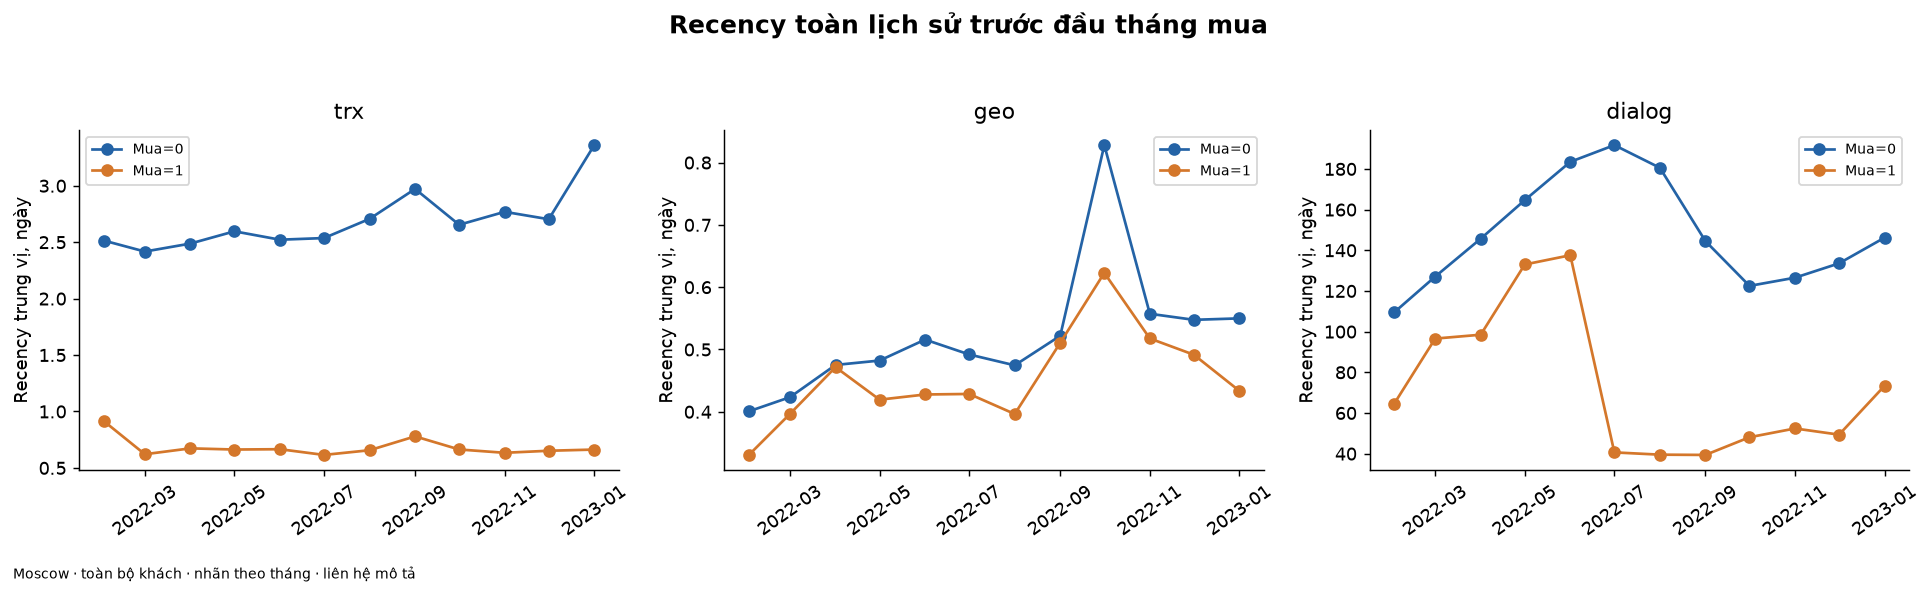

**outputs/eda_figures_moscow/lifecycle_coverage_denominators.png**

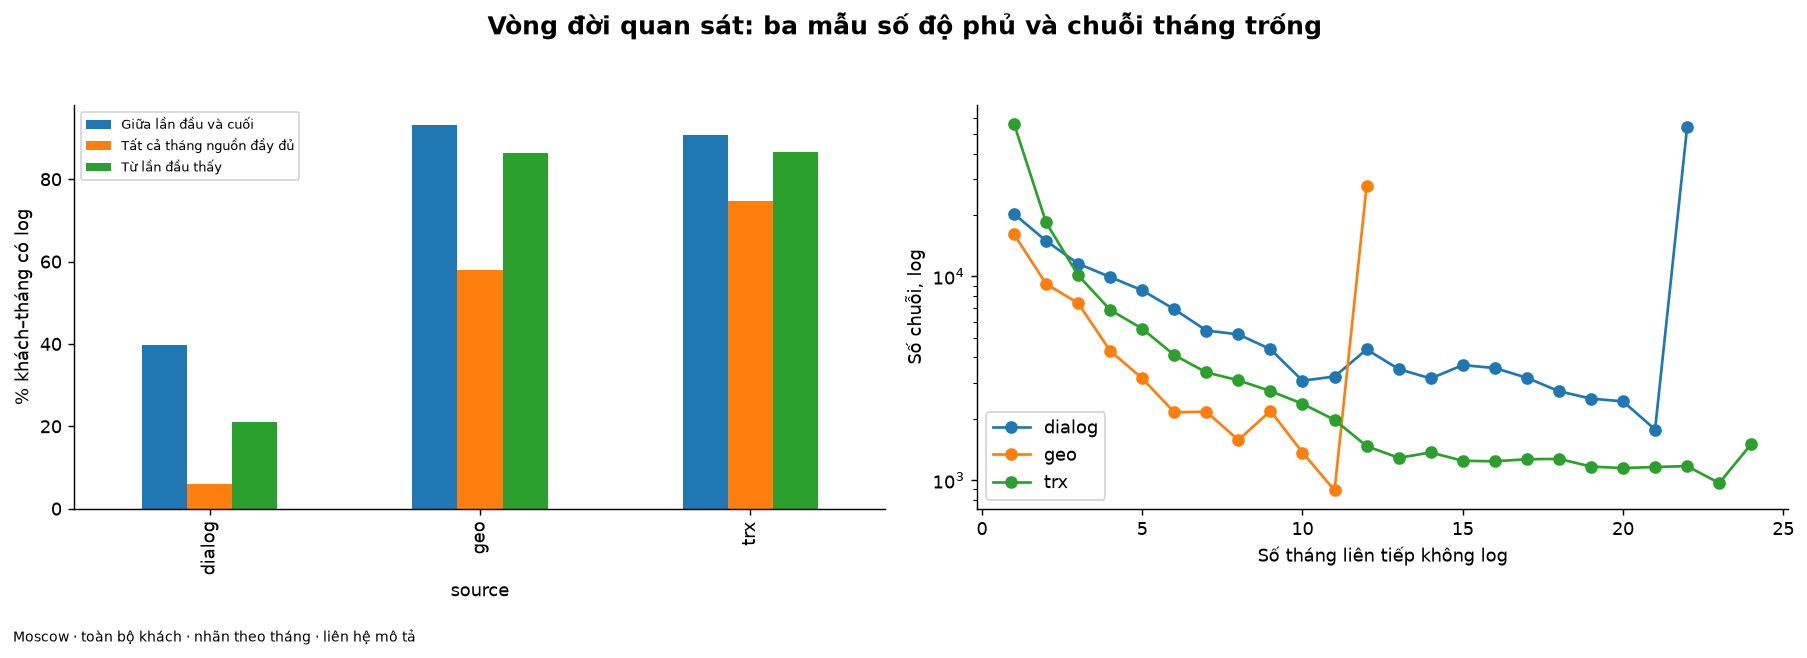

**outputs/eda_figures_moscow/lifecycle_first_observed_cohorts.png**

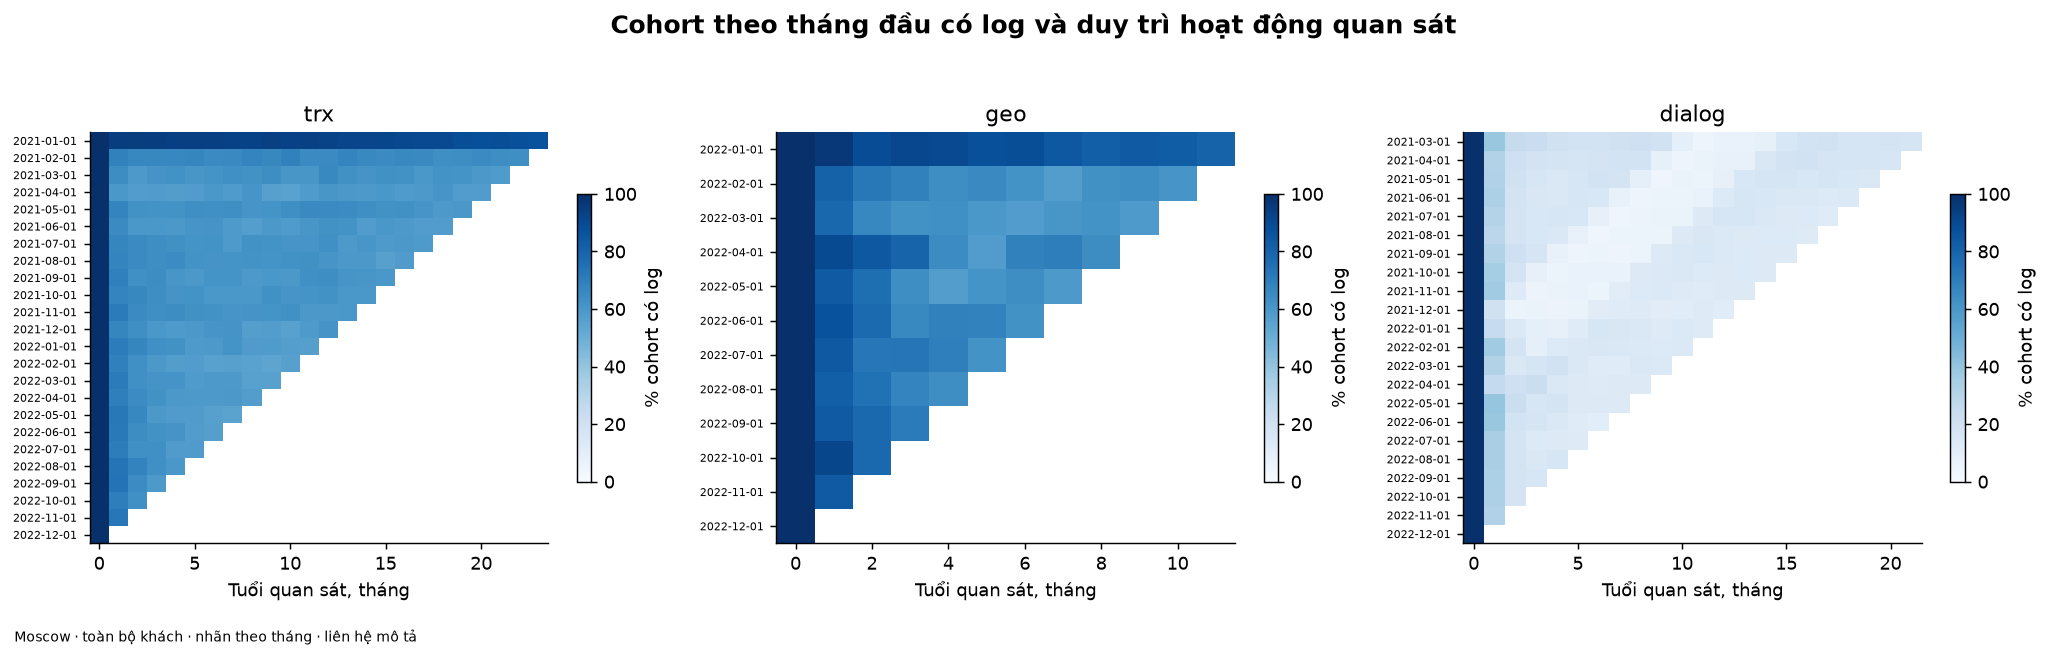

**outputs/eda_figures_moscow/all_history_recency_by_purchase_month.csv** — 5 dòng đầu

,source,anchor,purchase,population,defined,no_prior_observed_event,mean_days,median_days
0,trx,2022-02-01,0,99183,86061,13122,19.879890,2.514619
1,trx,2022-02-01,1,1041,939,102,7.603100,0.915440
2,trx,2022-03-01,0,98657,86476,12181,20.354566,2.416991
3,trx,2022-03-01,1,1567,1462,105,5.640173,0.621175
4,trx,2022-04-01,0,98526,87474,11052,21.182449,2.487687


**outputs/eda_figures_moscow/figure_index.csv** — 5 dòng đầu

,figure,title,data,explanation
0,baseline_amount11,amount11: thay đổi so với nền của chính khách,baseline_amount11.csv,baseline_amount11.md
1,baseline_dialog,dialog: thay đổi so với nền của chính khách,baseline_dialog.csv,baseline_dialog.md
2,baseline_event_type_new_cells,event_type_new_cells: thay đổi so với nền của ...,baseline_event_type_new_cells.csv,baseline_event_type_new_cells.md
3,baseline_event_type_unique_cells,event_type_unique_cells: thay đổi so với nền c...,baseline_event_type_unique_cells.csv,baseline_event_type_unique_cells.md
4,baseline_geo,geo: thay đổi so với nền của chính khách,baseline_geo.csv,baseline_geo.md


**outputs/eda_figures_moscow/lifecycle_coverage_denominators.csv** — 5 dòng đầu

,source,denominator,customer_months,active_customer_months,coverage,no_log_customers,population
0,trx,Tất cả tháng nguồn đầy đủ,2405376,1794395,0.745994,1503,100224
1,trx,Từ lần đầu thấy,2069575,1794395,0.867036,1503,100224
2,trx,Giữa lần đầu và cuối,1977114,1794395,0.907583,1503,100224
3,geo,Tất cả tháng nguồn đầy đủ,1202688,697180,0.579685,27676,100224
4,geo,Từ lần đầu thấy,807391,697180,0.863497,27676,100224


... (3 outputs left out)

,source,active,length_months,runs
0,trx,0,8,3088
1,trx,1,1,44570
2,trx,0,1,56033
3,trx,1,14,1608
4,trx,0,19,1166


**outputs/eda_figures_moscow/observed_day_boundary_gaps.csv** — 5 dòng đầu

,source,metric,defined_customers,undefined_customers,median,p90
0,trx,count,98721,1503,141.000000,518.000000
1,trx,median,96638,3586,2.483022,17.238573
2,trx,mean,96638,3586,4.019627,28.737532
3,trx,max,96638,3586,25.887139,154.309693
4,trx,cv,94946,5278,0.906911,1.736283


File kết quả khác: `outputs/eda_figures_moscow/all_history_recency_by_purchase_month.md`, `outputs/eda_figures_moscow/execution_status.json`, `outputs/eda_figures_moscow/lifecycle_coverage_denominators.md`, `outputs/eda_figures_moscow/lifecycle_first_observed_cohorts.md`

In [5]:
show_generated_results(__eda_started_ns, 'src/scripts/extend_eda_lifecycle.py')

## Extend Eda Monthly Features

Nguồn: `src/scripts/extend_eda_monthly_features.py`. Chạy các ô của phần này theo thứ tự.

In [6]:
__file__ = str(ROOT / 'src/scripts/extend_eda_monthly_features.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [7]:
"""Full population categorical profiles and fixed pre-window TRX strata."""
import json
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from complete_eda_figures_moscow import ROOT, OUT, BASE, load, publish, INDEX, event_studies

In [8]:
def main():
    ids,months,arrays,y=load();c=duckdb.connect();c.execute("SET memory_limit='3GB'");c.execute('SET threads=2')
    c.execute(f"SET temp_directory='{OUT.as_posix()}/tmp_monthly_features'")
    inventory=pd.read_csv(BASE/'source_inventory.csv').set_index('source')
    for source,r in inventory.iterrows():
        if r.first_month_partial:
            arrays[source][:,months.get_loc(pd.Timestamp(r.first_month))]=np.nan
    feature_arrays={};summaries=[]
    for source,levels in [('geo',['geohash_4','geohash_5','geohash_6']),('trx',['event_type'])]:
        raw=(ROOT/f'data/MBD-mini/detail/{source}/**/*.parquet').as_posix()
        for col in levels:
            print('Monthly categories',col,flush=True)
            cache=OUT/f'{col}_monthly_customer_cells.parquet'
            if not cache.exists():
                c.execute(f"COPY (SELECT client_id,date_trunc('month',event_time+INTERVAL '3 hours') AS month,{col} AS cell,count(*) AS events FROM read_parquet('{raw}') GROUP BY 1,2,3) TO '{cache.as_posix()}' (FORMAT PARQUET)")
            path=cache.as_posix()
            profile=c.execute(f"""WITH cells AS (
              SELECT *,sum(events) OVER(PARTITION BY client_id,month) total,
                min(month) OVER(PARTITION BY client_id,cell) first_cell_month,
                row_number() OVER(PARTITION BY client_id,month ORDER BY events DESC,cell) rank
              FROM read_parquet('{path}'))
              SELECT client_id,month,count(*) unique_cells,
                max(events)::DOUBLE/max(total) top_share,
                -sum((events::DOUBLE/total)*ln(events::DOUBLE/total)) entropy,
                sum(pow(events::DOUBLE/total,2)) hhi,
                count(*) FILTER(WHERE first_cell_month=month) new_cells,
                sum(CASE WHEN first_cell_month=month THEN events ELSE 0 END)::DOUBLE/max(total) new_cell_event_share,
                max(CASE WHEN rank=1 THEN cell END) main_cell,
                max(total) events
              FROM cells GROUP BY 1,2""").df()
            profile=profile.sort_values(['client_id','month'])
            profile['previous_main']=profile.groupby('client_id').main_cell.shift()
            profile['previous_month']=profile.groupby('client_id').month.shift()
            consecutive=profile.month.eq(profile.previous_month+pd.offsets.MonthBegin(1))
            profile['changed_main']=np.where(consecutive,profile.main_cell.ne(profile.previous_main).astype(float),np.nan)
            profile.to_parquet(OUT/f'{col}_monthly_profiles.parquet',index=False)
            first=pd.Timestamp(inventory.loc[source,'first_month']);last=pd.Timestamp(inventory.loc[source,'last_month'])
            valid=(months>=first)&(months<=last)
            if inventory.loc[source,'first_month_partial']:valid &= months!=first
            for metric in ['unique_cells','top_share','entropy','hhi','new_cells','new_cell_event_share','changed_main']:
                a=profile.pivot(index='client_id',columns='month',values=metric).reindex(index=ids,columns=months).to_numpy(dtype=float,copy=True)
                # Zero counts are defined without log; concentration/entropy/change remain unknown.
                if metric in ['unique_cells','new_cells']:a=np.nan_to_num(a)
                a[:,~valid]=np.nan
                summaries.append(dict(source=source,column=col,metric=metric,defined_customer_months=int(np.isfinite(a).sum()),
                    undefined_customer_months=int((~np.isfinite(a)).sum()),median=float(np.nanmedian(a))))
                if col in ['geohash_4','event_type'] and metric in ['unique_cells','new_cells']:
                    feature_arrays[f'{col}_{metric}']=a
            # Compact monthly source-level summary, retaining undefined customer counts.
            fig,axes=plt.subplots(2,2,figsize=(13,7))
            for ax,metric in zip(axes.flat,['top_share','entropy','new_cell_event_share','changed_main']):
                q=profile.groupby('month')[metric].agg(['mean','median','count'])
                ax.plot(q.index,q['mean'],'o-',label='Mean khách có chỉ tiêu');ax.plot(q.index,q['median'],':',label='Median')
                ax.set_title(metric);ax.legend(fontsize=7);ax.tick_params(axis='x',rotation=30)
            publish(f'{col}_monthly_concentration_novelty',fig,profile.groupby('month').agg(customers=('client_id','size'),mean_entropy=('entropy','mean'),mean_topshare=('top_share','mean'),mean_new_event_share=('new_cell_event_share','mean'),changed_main_defined=('changed_main','count'),changed_main_share=('changed_main','mean')).reset_index(),
                f'{col}: tập trung, độ mới và đổi mã chính theo tháng',
                'Tất cả sự kiện; nhóm khách–tháng–mã. Mã mới là chưa thấy ở bất kỳ tháng trước trong toàn lịch sử được cung cấp; '
                'tỷ lệ mới là số sự kiện tại mã lần đầu thấy tháng này / tổng sự kiện tháng. Mã chính chọn count lớn nhất, tie mã nhỏ nhất. '
                'Đổi mã chỉ tính khi hai tháng liền nhau đều có log. Bảng cá thể đầy đủ lưu Parquet.',
                'Đo diễn tiến cấu trúc danh mục và mức mới trong phạm vi quan sát; concentration chỉ xác định khi có log.',
                f'Kiểm kê {profile.client_id.nunique():,} khách có nguồn, {len(profile):,} khách–tháng có log. '
                f'Entropy trung vị {profile.entropy.median():.4g}; top-share trung vị {profile.top_share.median():.4g}.',
                'Các đường mô tả khách có log, số undefined đọc bảng tổng hợp; không đại diện mọi khách. '
                'Tháng đầu nguồn được giữ trong hình kiểm kê, là tháng không trọn với GEO. Đổi mã không chứng minh di chuyển hoặc đổi nghiệp vụ.')
    c.close()
    pd.DataFrame(summaries).to_csv(OUT/'monthly_categorical_feature_coverage.csv',index=False)
    event_studies(ids,months,feature_arrays,y)
    # Fixed strata before beginning the -3..+3 observation region.
    rows=[];anchors=np.where(np.isfinite(y).any(axis=0))[0]
    for t in anchors:
        if t<3:continue
        hist=arrays['trx'][:,:t-3]
        known_months=np.isfinite(hist).any(axis=0)
        if not known_months.any():continue
        counts=np.nansum(hist,axis=1)
        pos=counts>0
        edges=np.unique(np.quantile(counts[pos],[.2,.4,.6,.8])) if pos.any() else np.array([])
        strata=np.where(pos,np.searchsorted(edges,counts,side='left')+1,0)
        for source in ['trx','geo','dialog']:
            a=arrays[source]
            for lag in range(-3,4):
                j=t+lag;v=a[:,j] if 0<=j<a.shape[1] else np.full(len(ids),np.nan)
                for b in [0,1]:
                    for s in range(int(strata.max())+1):
                        mask=(y[:,t]==b)&(strata==s);good=mask&np.isfinite(v)
                        rows.append(dict(source=source,anchor=str(months[t].date()),lag=lag,purchase=b,stratum=s,
                            population=int(mask.sum()),observed=int(good.sum()),unavailable=int((mask&~np.isfinite(v)).sum()),
                            mean=float(v[good].mean()) if good.any() else np.nan))
    d=pd.DataFrame(rows)
    assert (d.observed+d.unavailable==d.population).all()
    assert d.groupby(['source','anchor','lag']).population.sum().eq(len(ids)).all()
    fig,axes=plt.subplots(3,6,figsize=(19,10),sharex=True)
    for row,source in enumerate(['trx','geo','dialog']):
        for s in range(6):
            ax=axes[row,s]
            for b,color in [(0,'#2463a6'),(1,'#d4772b')]:
                q=d[(d.source==source)&(d.stratum==s)&(d.purchase==b)].groupby('lag')['mean'].mean()
                ax.plot(q.index,q,'o-',ms=3,color=color,label=f'Mua={b}')
            ax.set_title(f'{source}, T{s}',fontsize=9);ax.axvline(0,color='gray',ls=':');ax.grid(alpha=.2)
    axes[0,0].legend(fontsize=7)
    publish('fixed_past_trx_strata_event_study',fig,d,'Trước/sau tháng mua trong tầng TRX xác định từ quá khứ',
        'T0 không thấy TRX; T1–T5 quintile count TRX dương trên toàn lịch sử trước đầu tháng −3; ties không chia. '
        'Tầng giữ cố định suốt −3..+3 của một tháng neo. Mỗi đường cân bằng trọng số tháng neo; CSV giữ đủ n/unknown theo kỳ. '
        'Các tháng neo không có bất kỳ tháng lịch sử nguồn trước −3 chưa đủ điều kiện và không tạo tầng giả.',
        'Kiểm tra khác biệt mua/không mua còn cùng chiều trong các mức hoạt động quá khứ hay không.',
        'Tổng các tầng và hai nhóm nhãn bằng 100.224 khách ở từng nguồn–tháng neo–lag đã tạo; '
        'không cộng các tầng giữa các tháng neo vì khách có thể chuyển tầng.',
        'Phân tầng count chưa kiểm soát độ dài lịch sử hoặc toàn bộ nhiễu. Chưa có CI từng đường. '
        'Khoảng không có log không chứng minh quan sát liên tục.')
    old=pd.read_csv(OUT/'figure_index.csv');idx=pd.concat([old,pd.DataFrame(INDEX)]).drop_duplicates('figure',keep='last');idx.to_csv(OUT/'figure_index.csv',index=False)
    status=json.loads((OUT/'execution_status.json').read_text(encoding='utf-8'));status['done']+=['geo_all_level_monthly_entropy_hhi_novelty_main_change','trx_monthly_type_entropy_novelty','fixed_pre_window_trx_strata_event_study'];status['figures']=len(idx)
    (OUT/'execution_status.json').write_text(json.dumps(status,ensure_ascii=False,indent=2),encoding='utf-8')

In [9]:
if __name__=='__main__':main()

Monthly categories geohash_4


Saved geohash_4_monthly_concentration_novelty


Monthly categories geohash_5


Saved geohash_5_monthly_concentration_novelty


Monthly categories geohash_6


Saved geohash_6_monthly_concentration_novelty


... (11 outputs left out)

Saved event_event_type_new_cells


Saved event_event_type_new_cells_by_anchor


Saved baseline_event_type_new_cells


Saved fixed_past_trx_strata_event_study


### Kết quả: `src/scripts/extend_eda_monthly_features.py`

**outputs/eda_figures_moscow/baseline_event_type_new_cells.png**

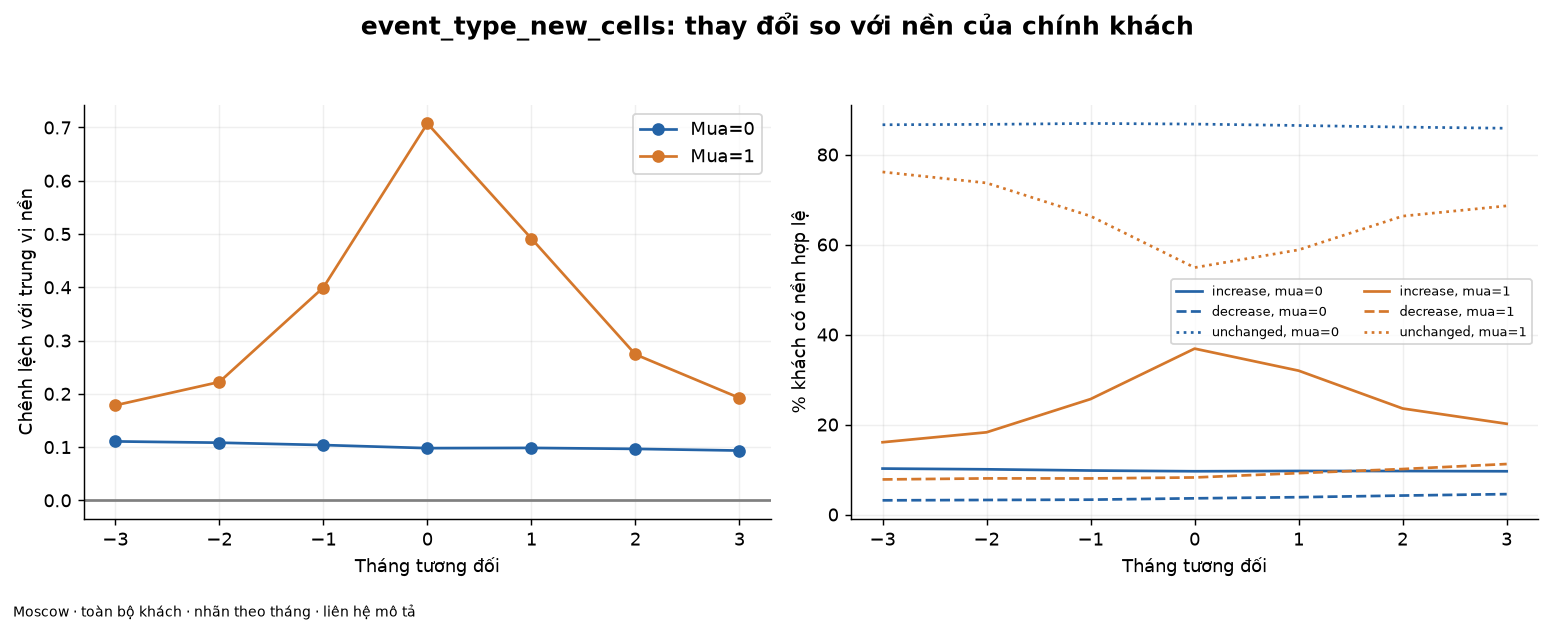

**outputs/eda_figures_moscow/baseline_event_type_unique_cells.png**

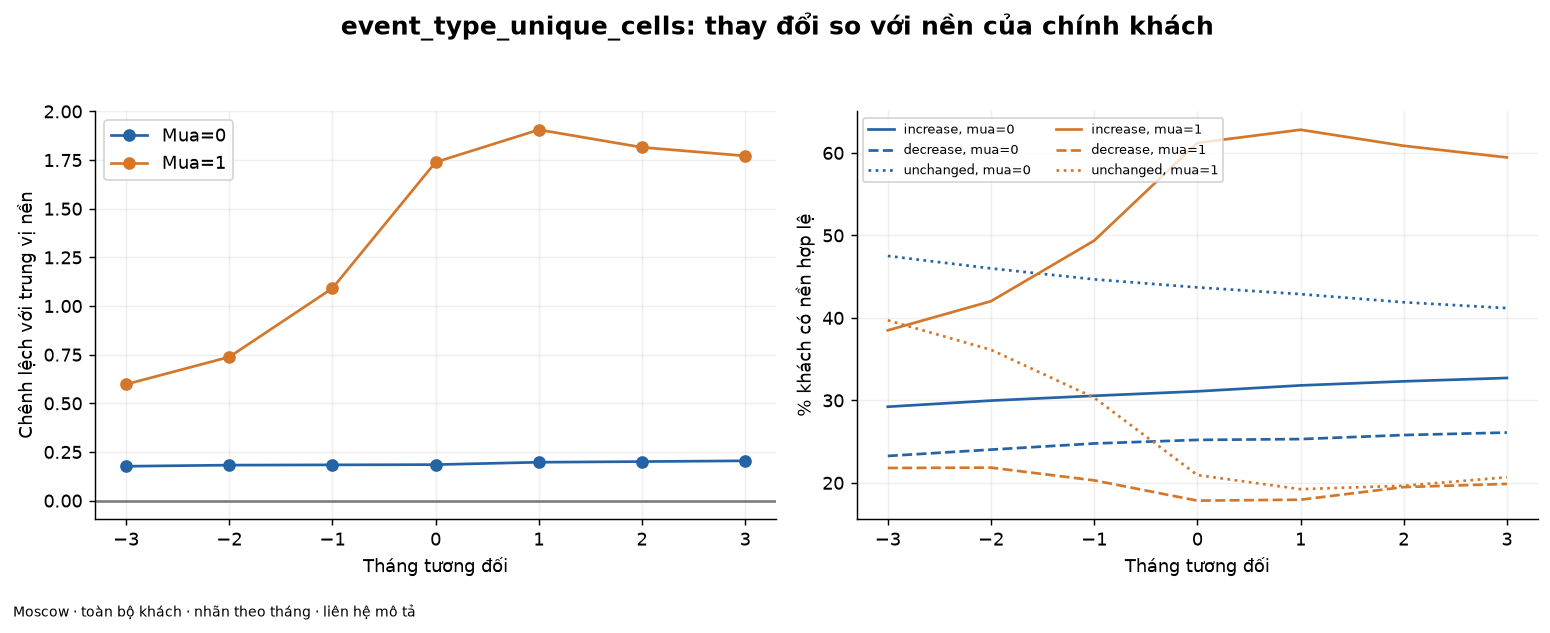

**outputs/eda_figures_moscow/baseline_geohash_4_new_cells.png**

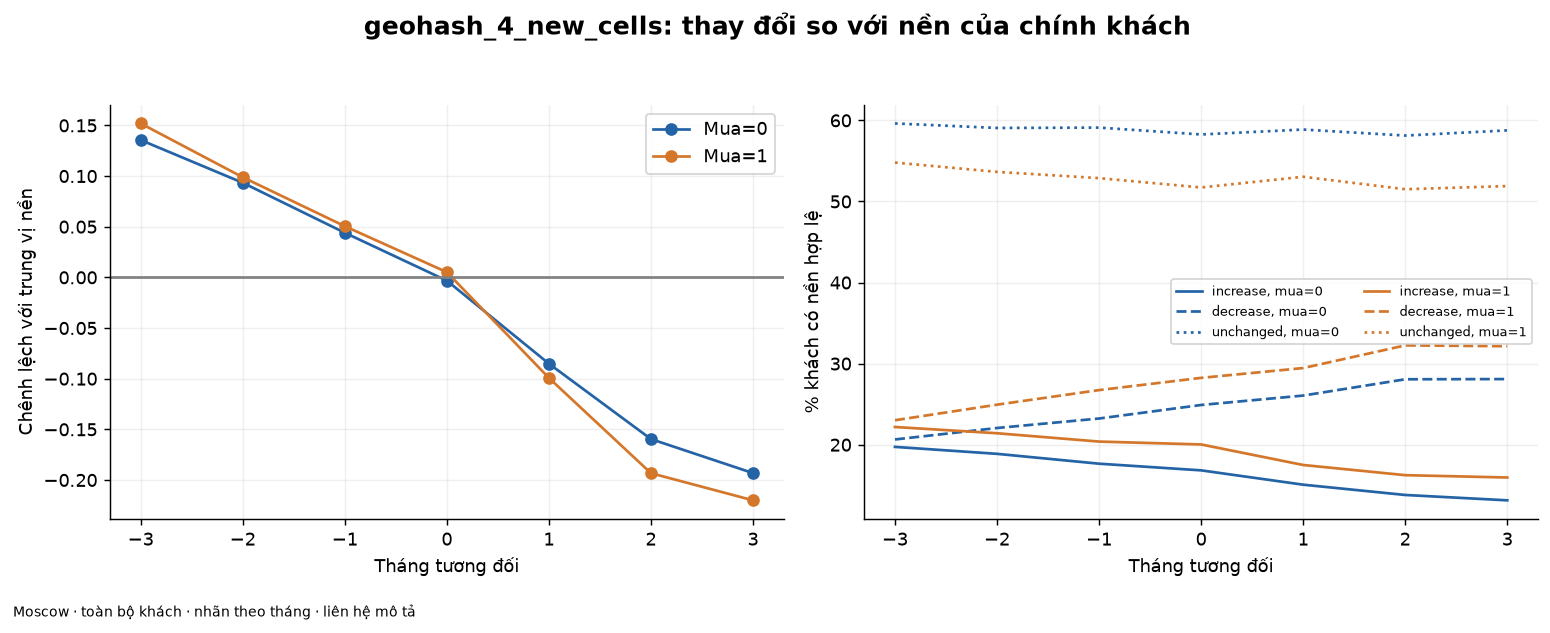

**outputs/eda_figures_moscow/baseline_geohash_4_unique_cells.png**

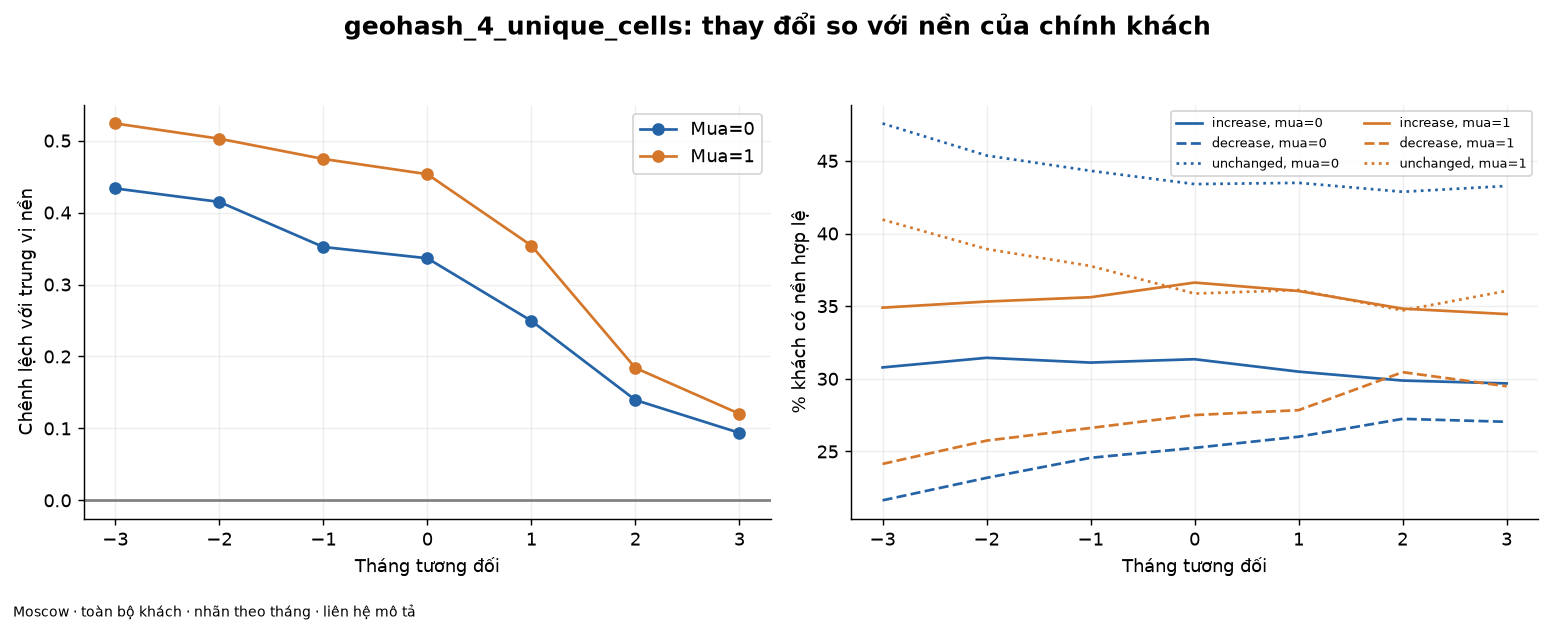

**outputs/eda_figures_moscow/event_event_type_new_cells.png**

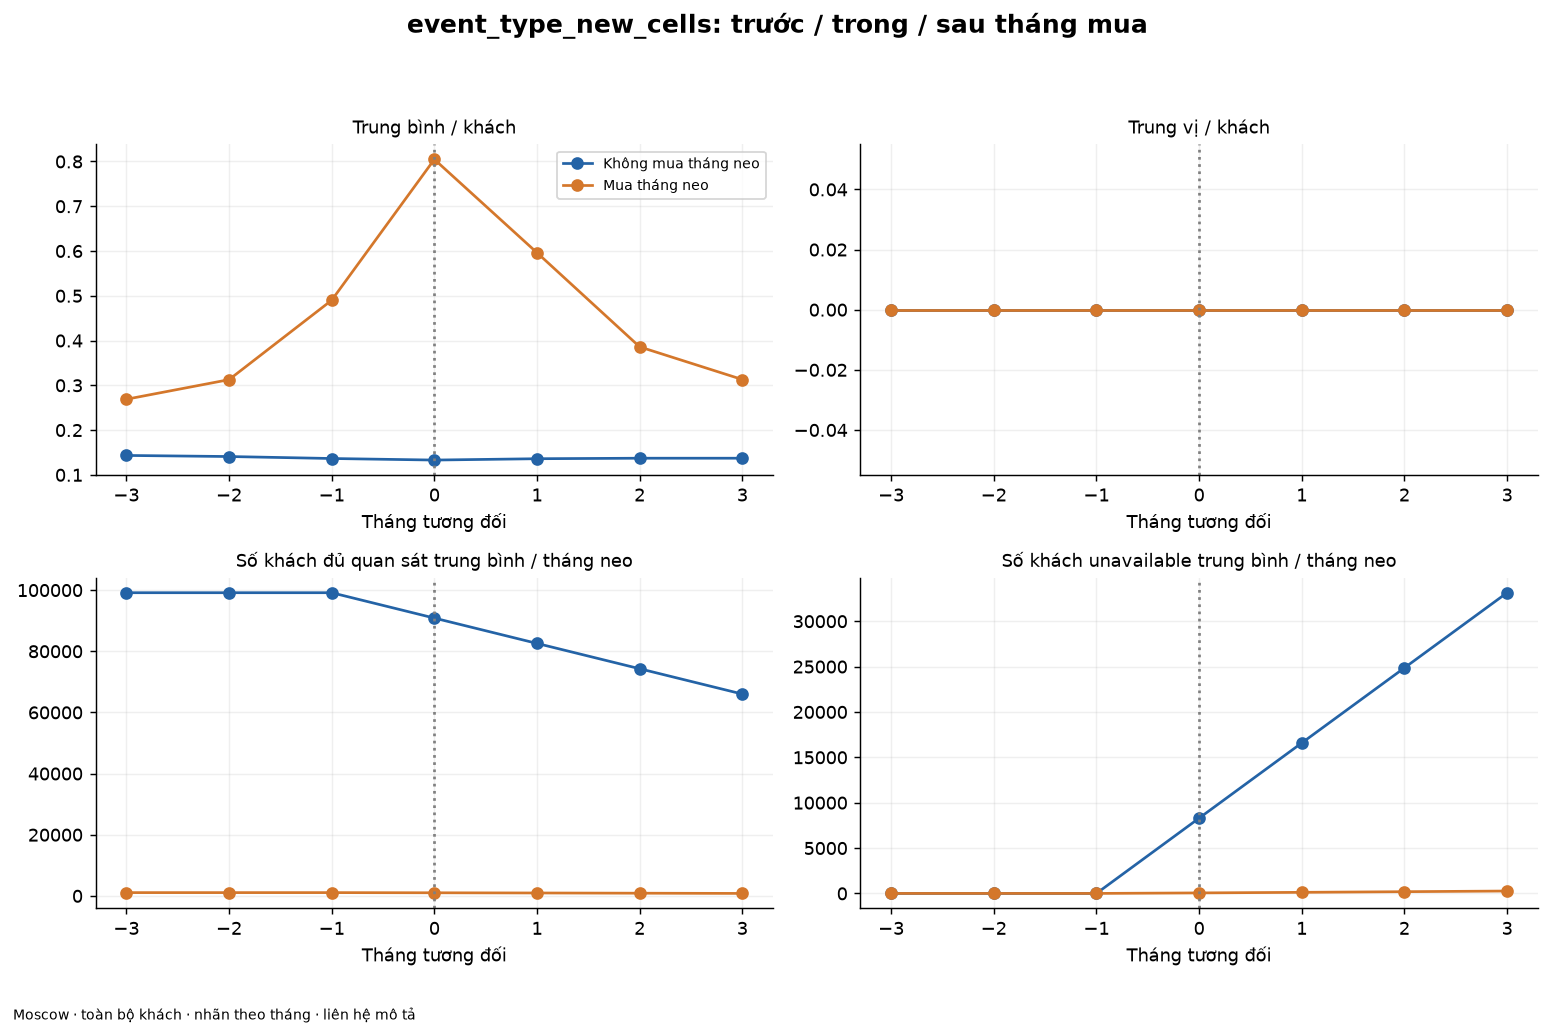

**outputs/eda_figures_moscow/event_event_type_new_cells_by_anchor.png**

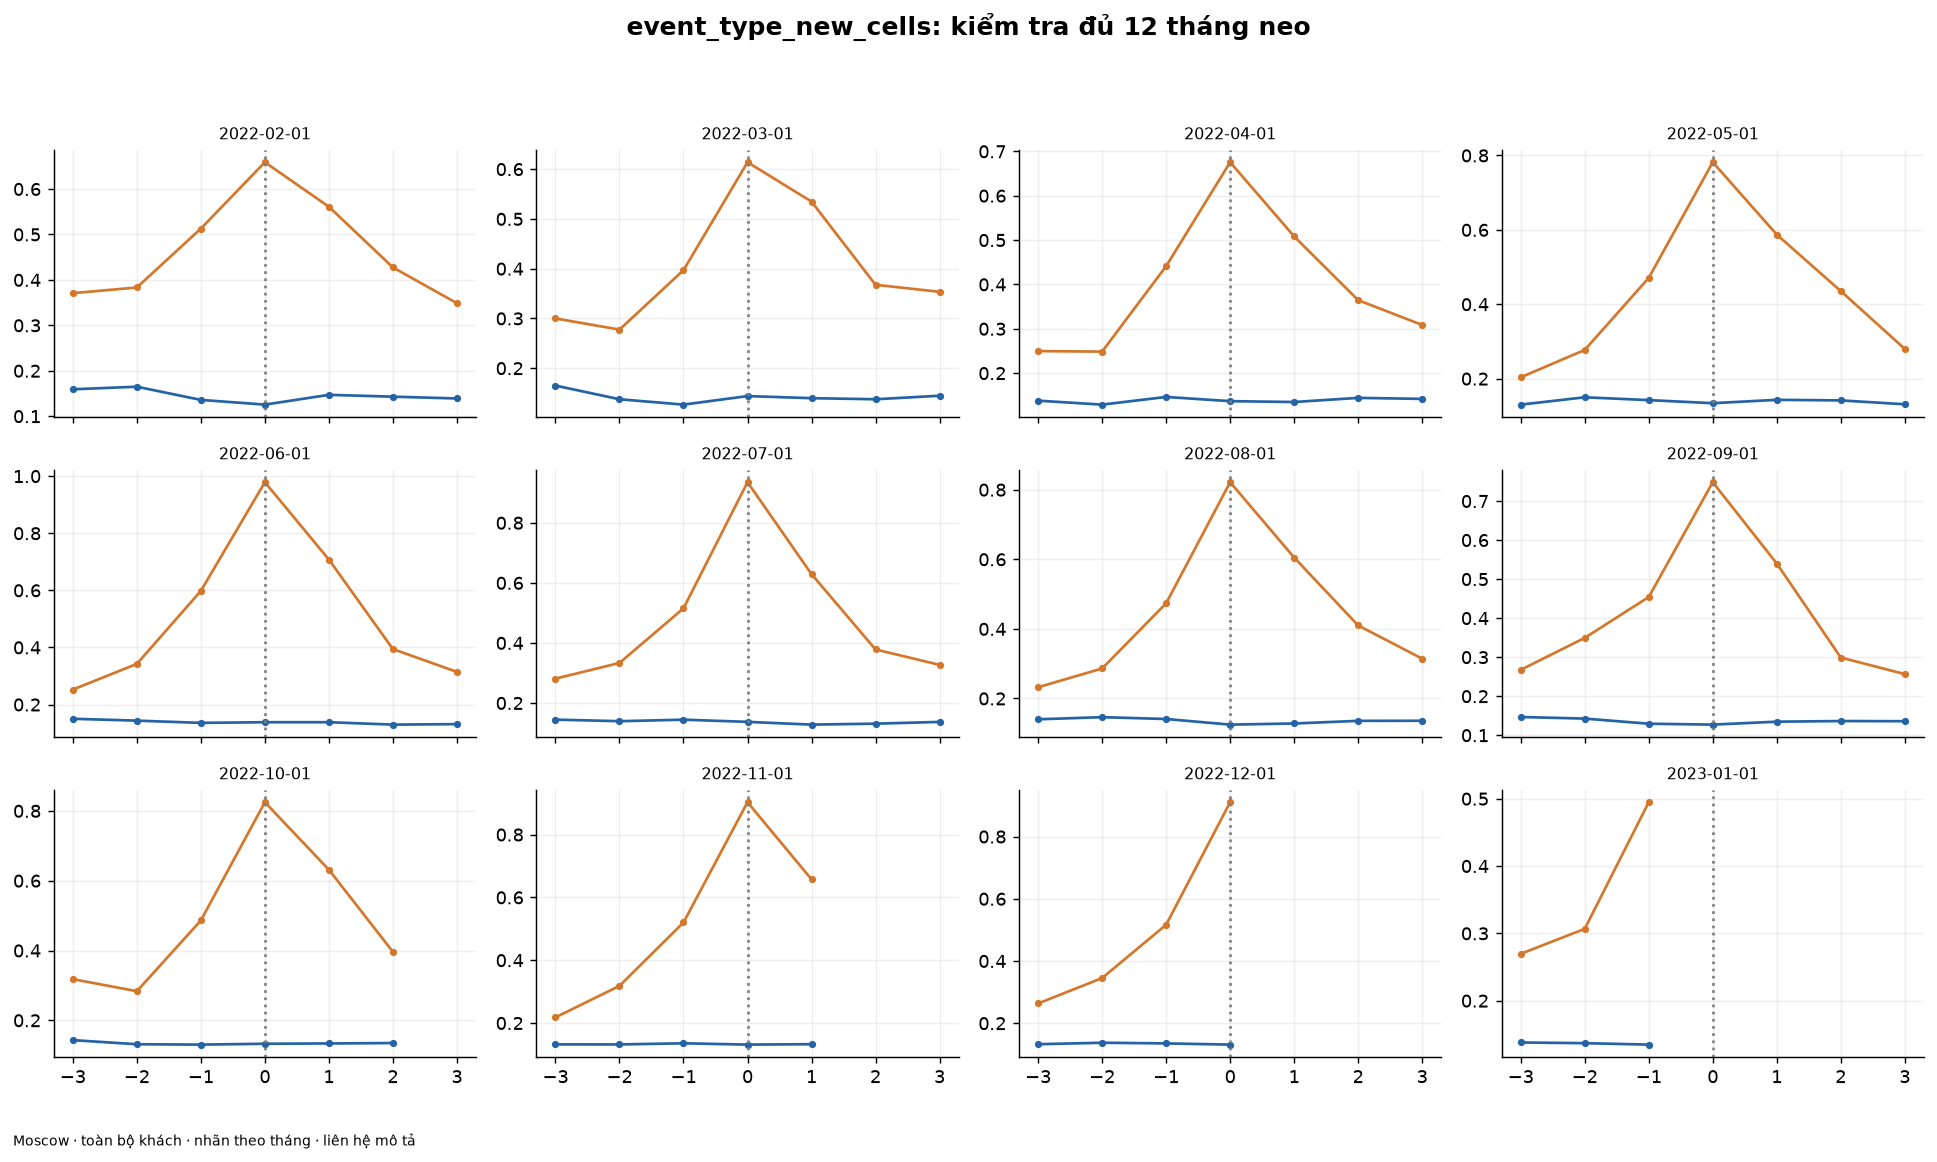

**outputs/eda_figures_moscow/event_event_type_unique_cells.png**

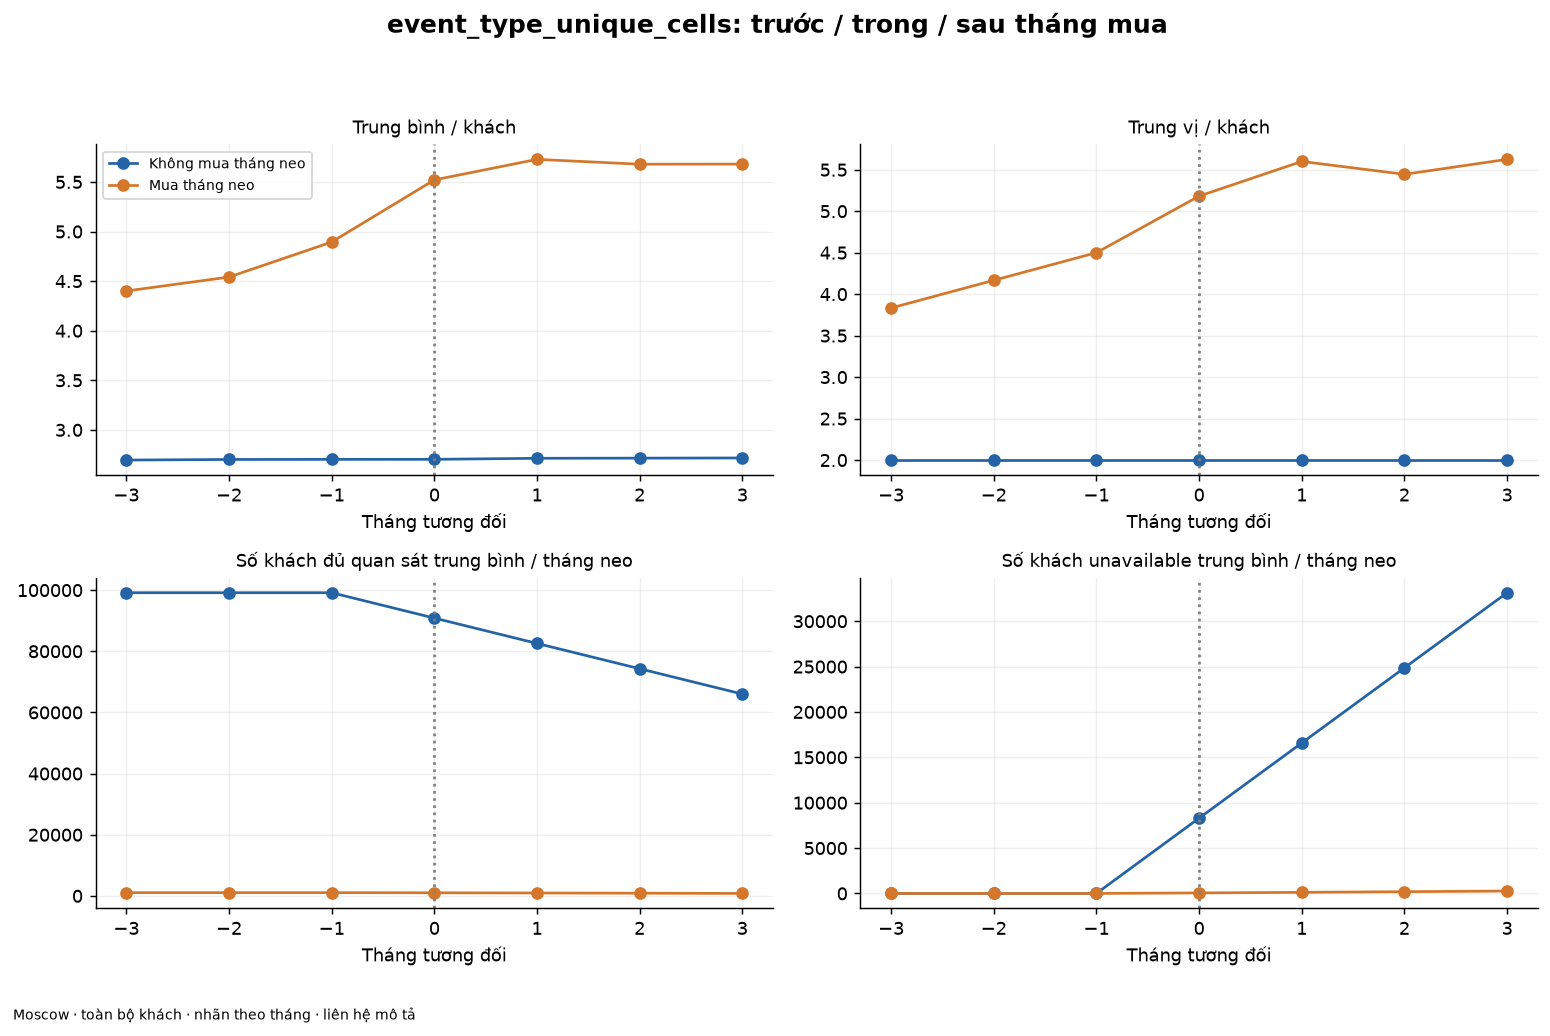

**outputs/eda_figures_moscow/event_event_type_unique_cells_by_anchor.png**

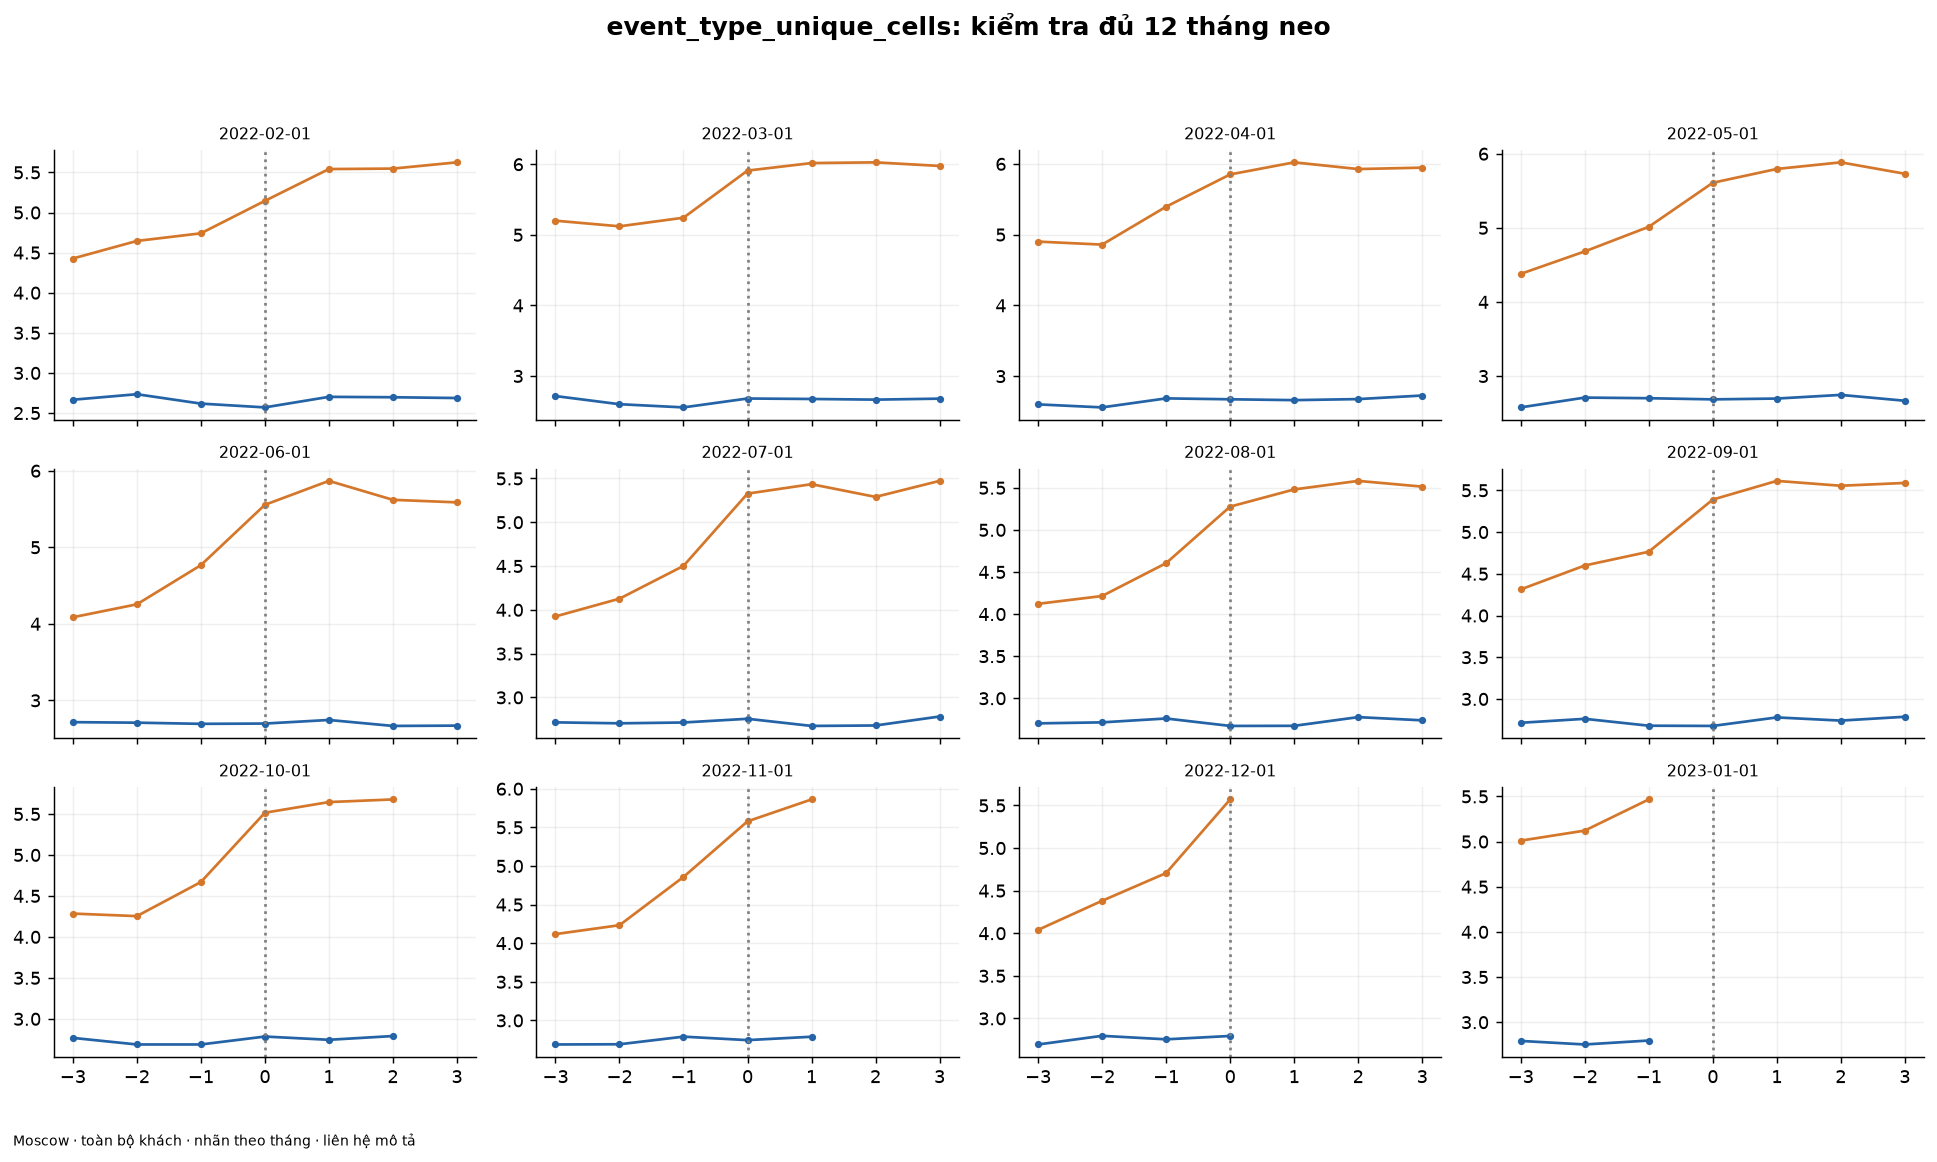

**outputs/eda_figures_moscow/event_geohash_4_new_cells.png**

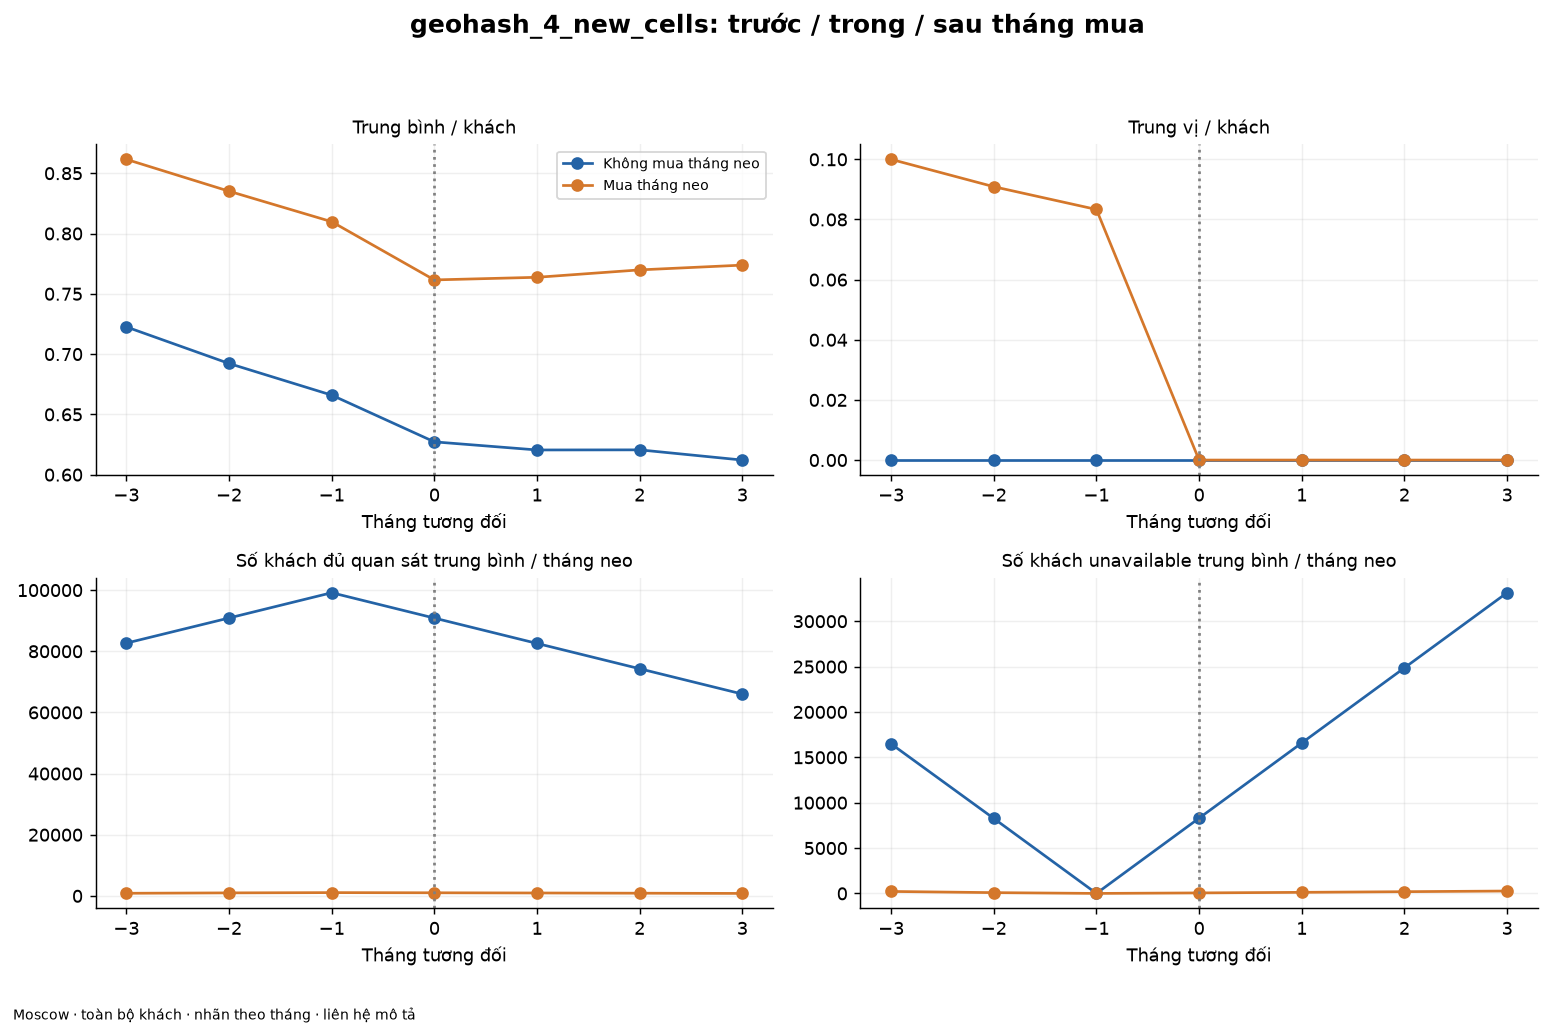

**outputs/eda_figures_moscow/event_geohash_4_new_cells_by_anchor.png**

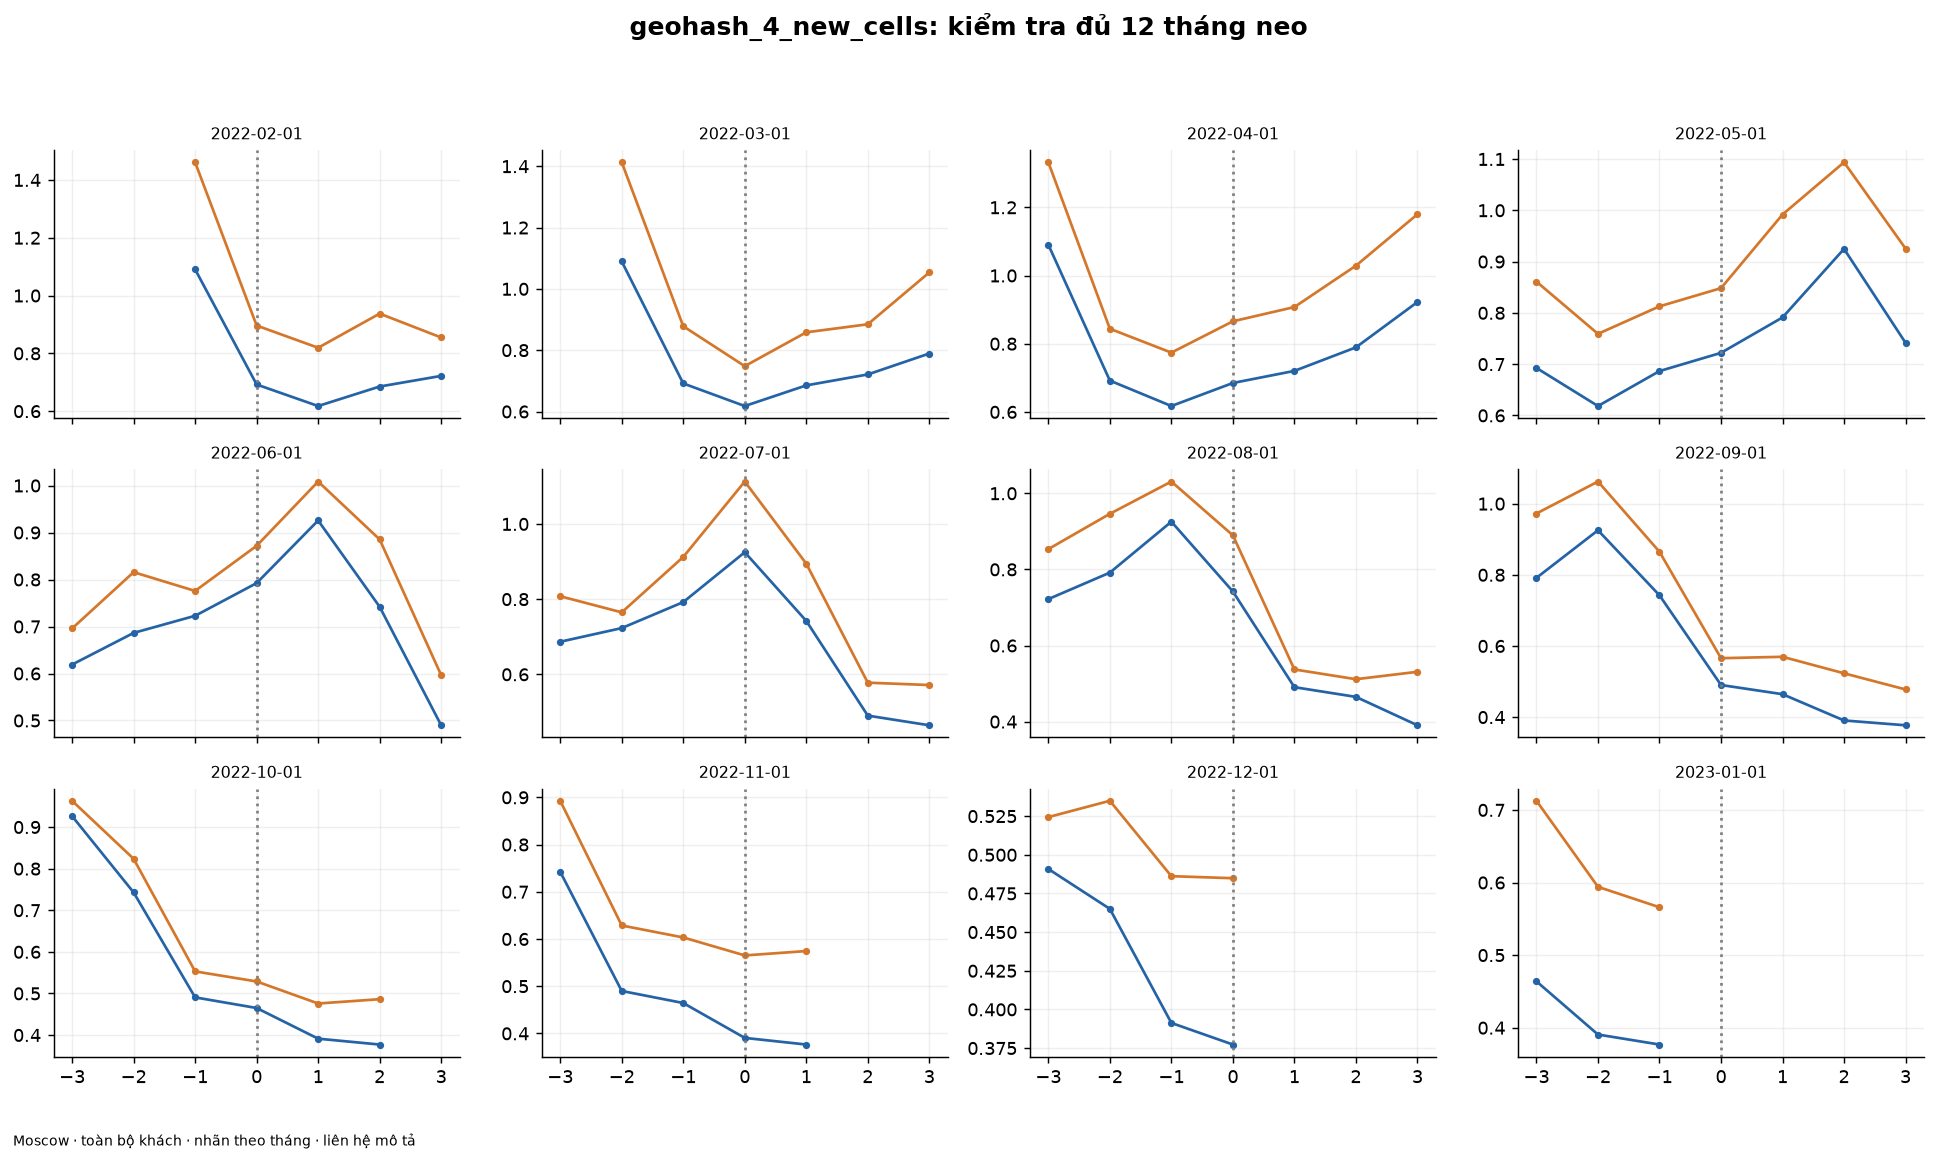

**outputs/eda_figures_moscow/event_geohash_4_unique_cells.png**

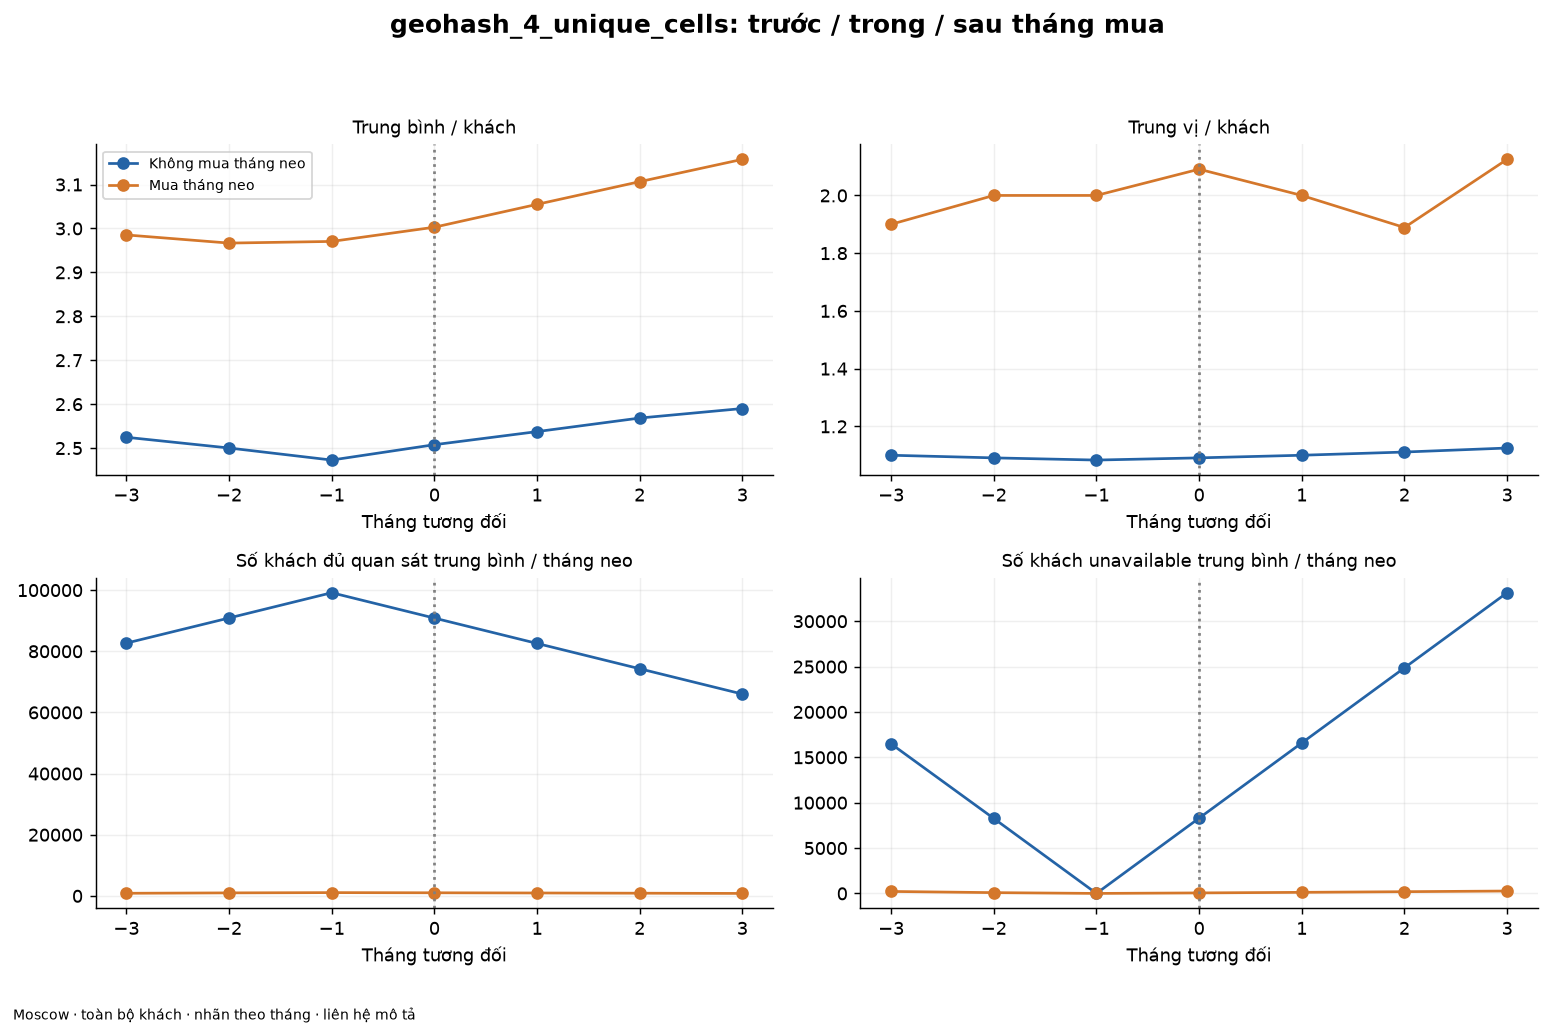

**outputs/eda_figures_moscow/event_geohash_4_unique_cells_by_anchor.png**

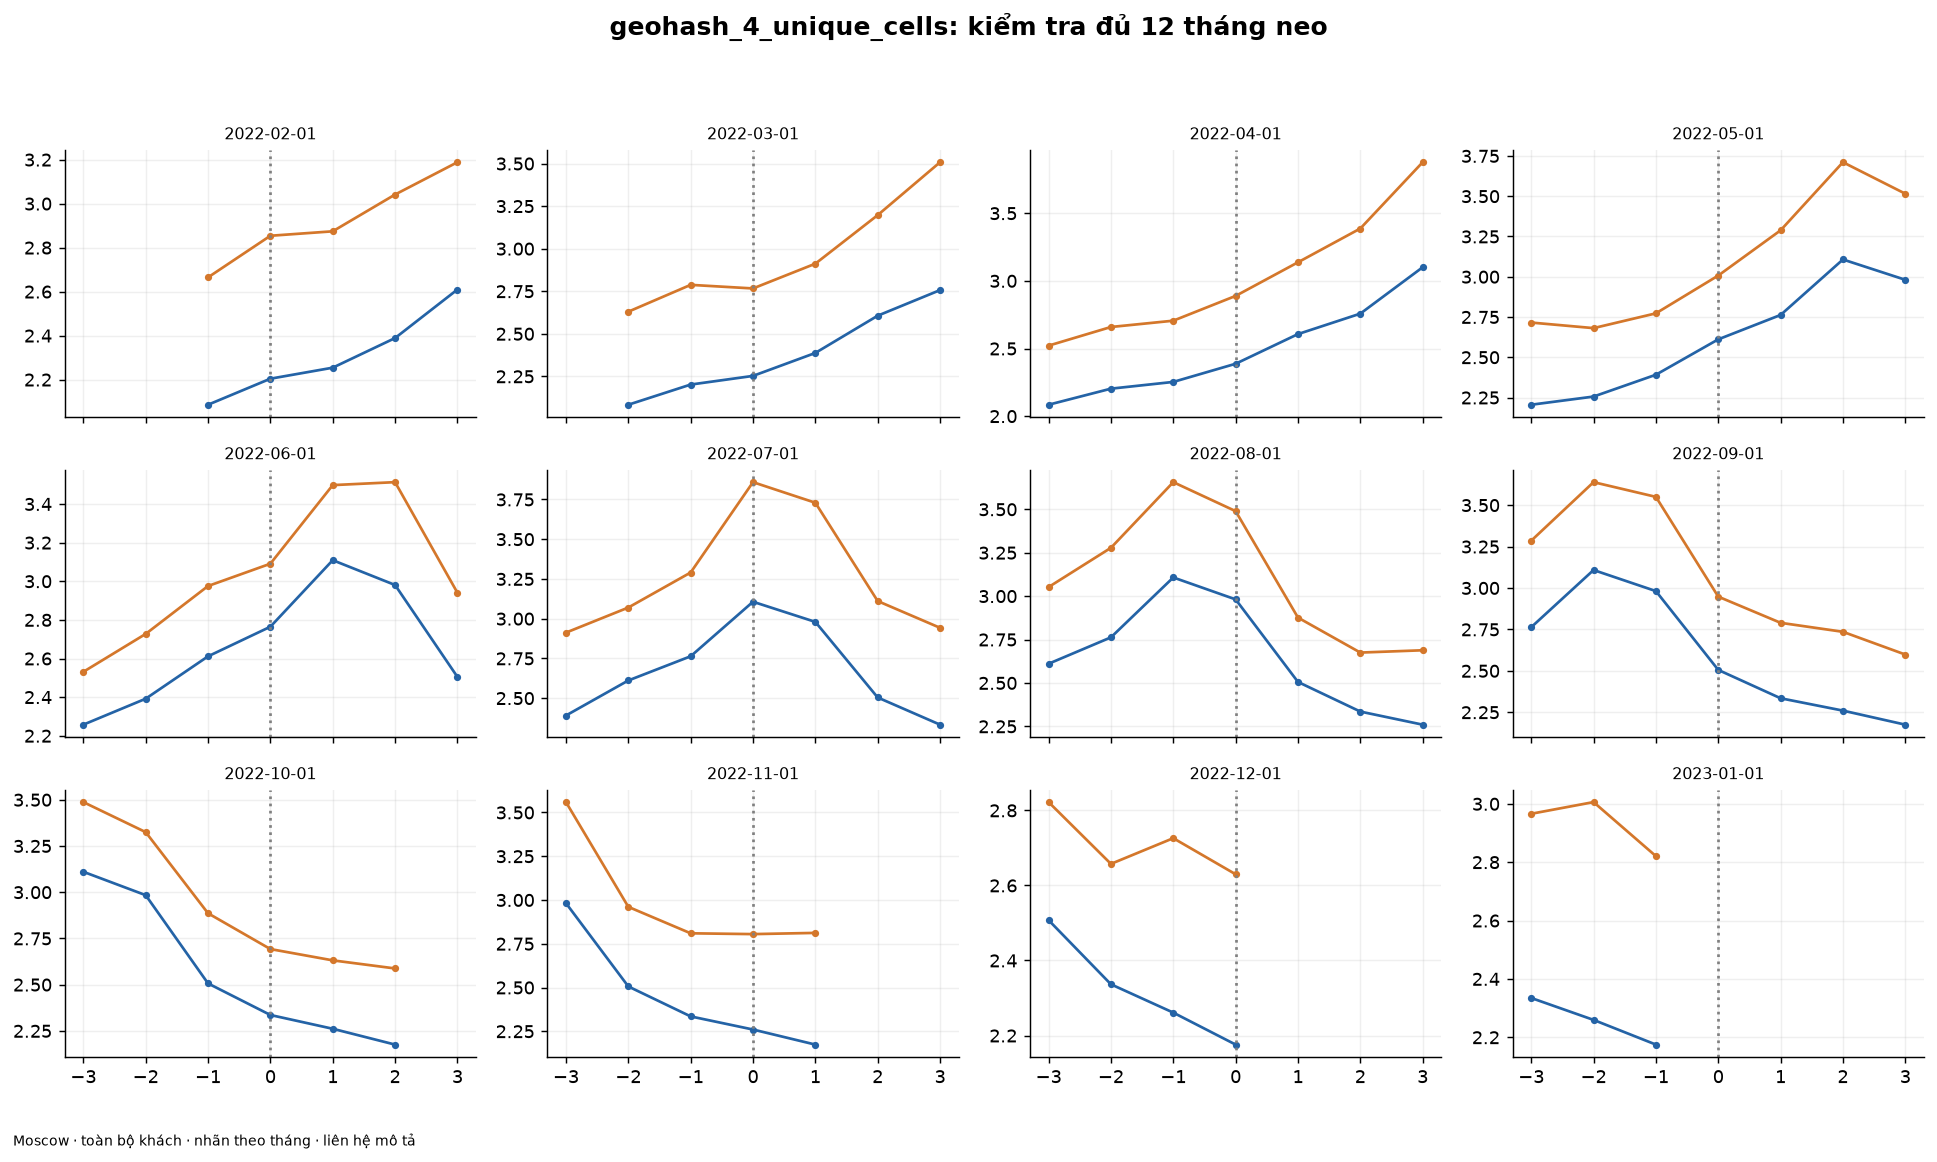

**outputs/eda_figures_moscow/event_type_monthly_concentration_novelty.png**

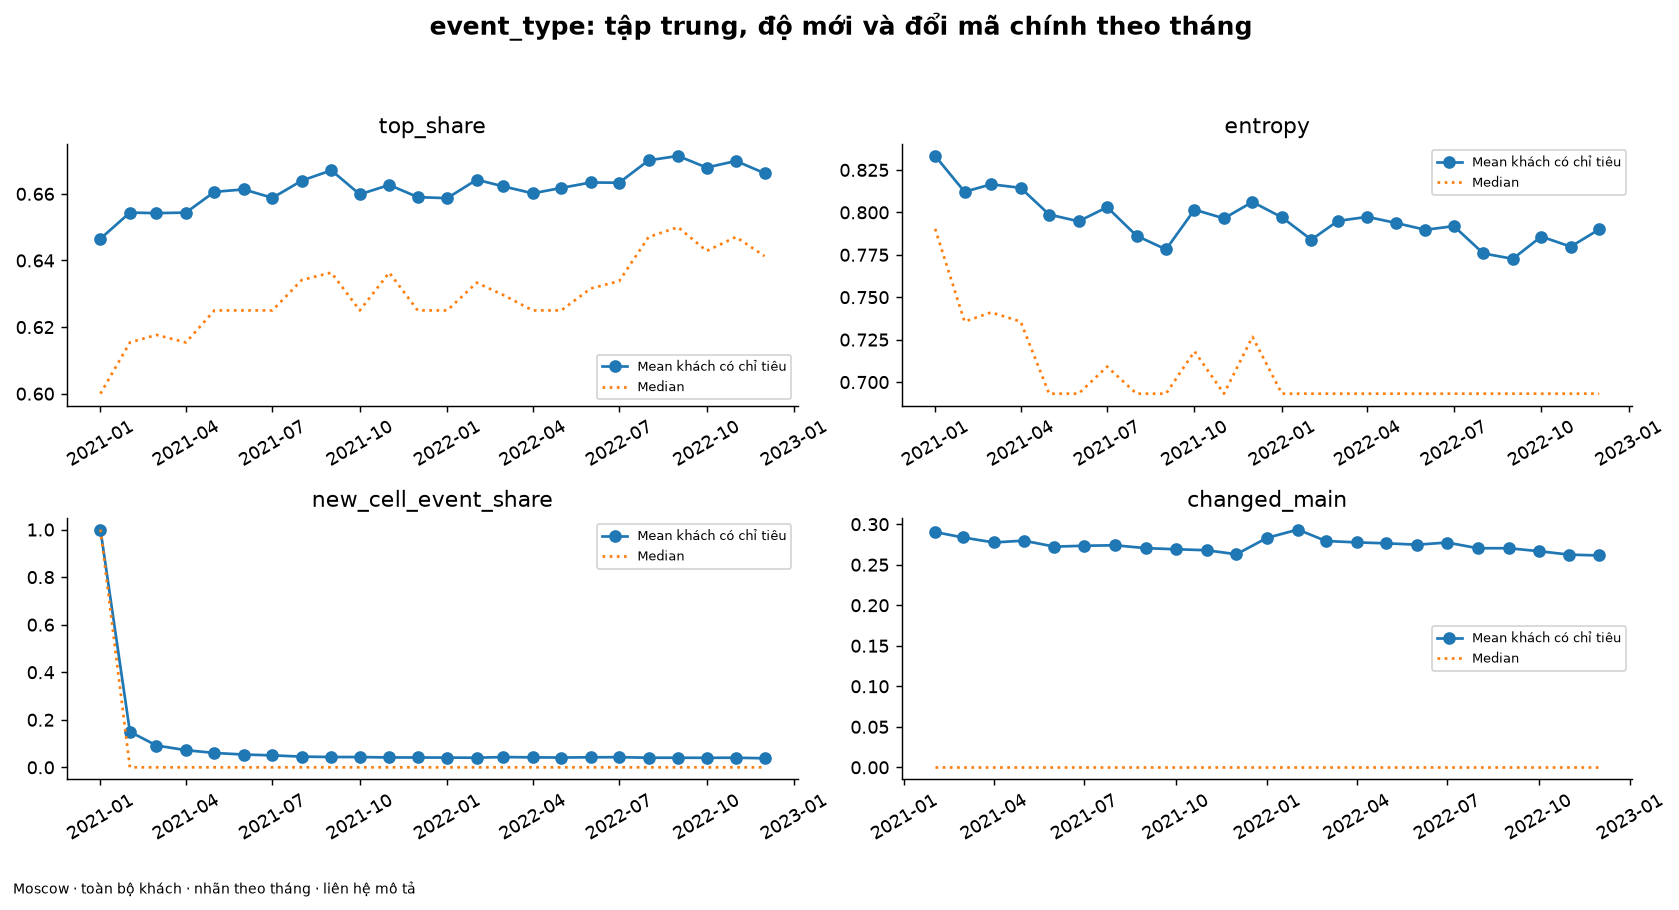

**outputs/eda_figures_moscow/fixed_past_trx_strata_event_study.png**

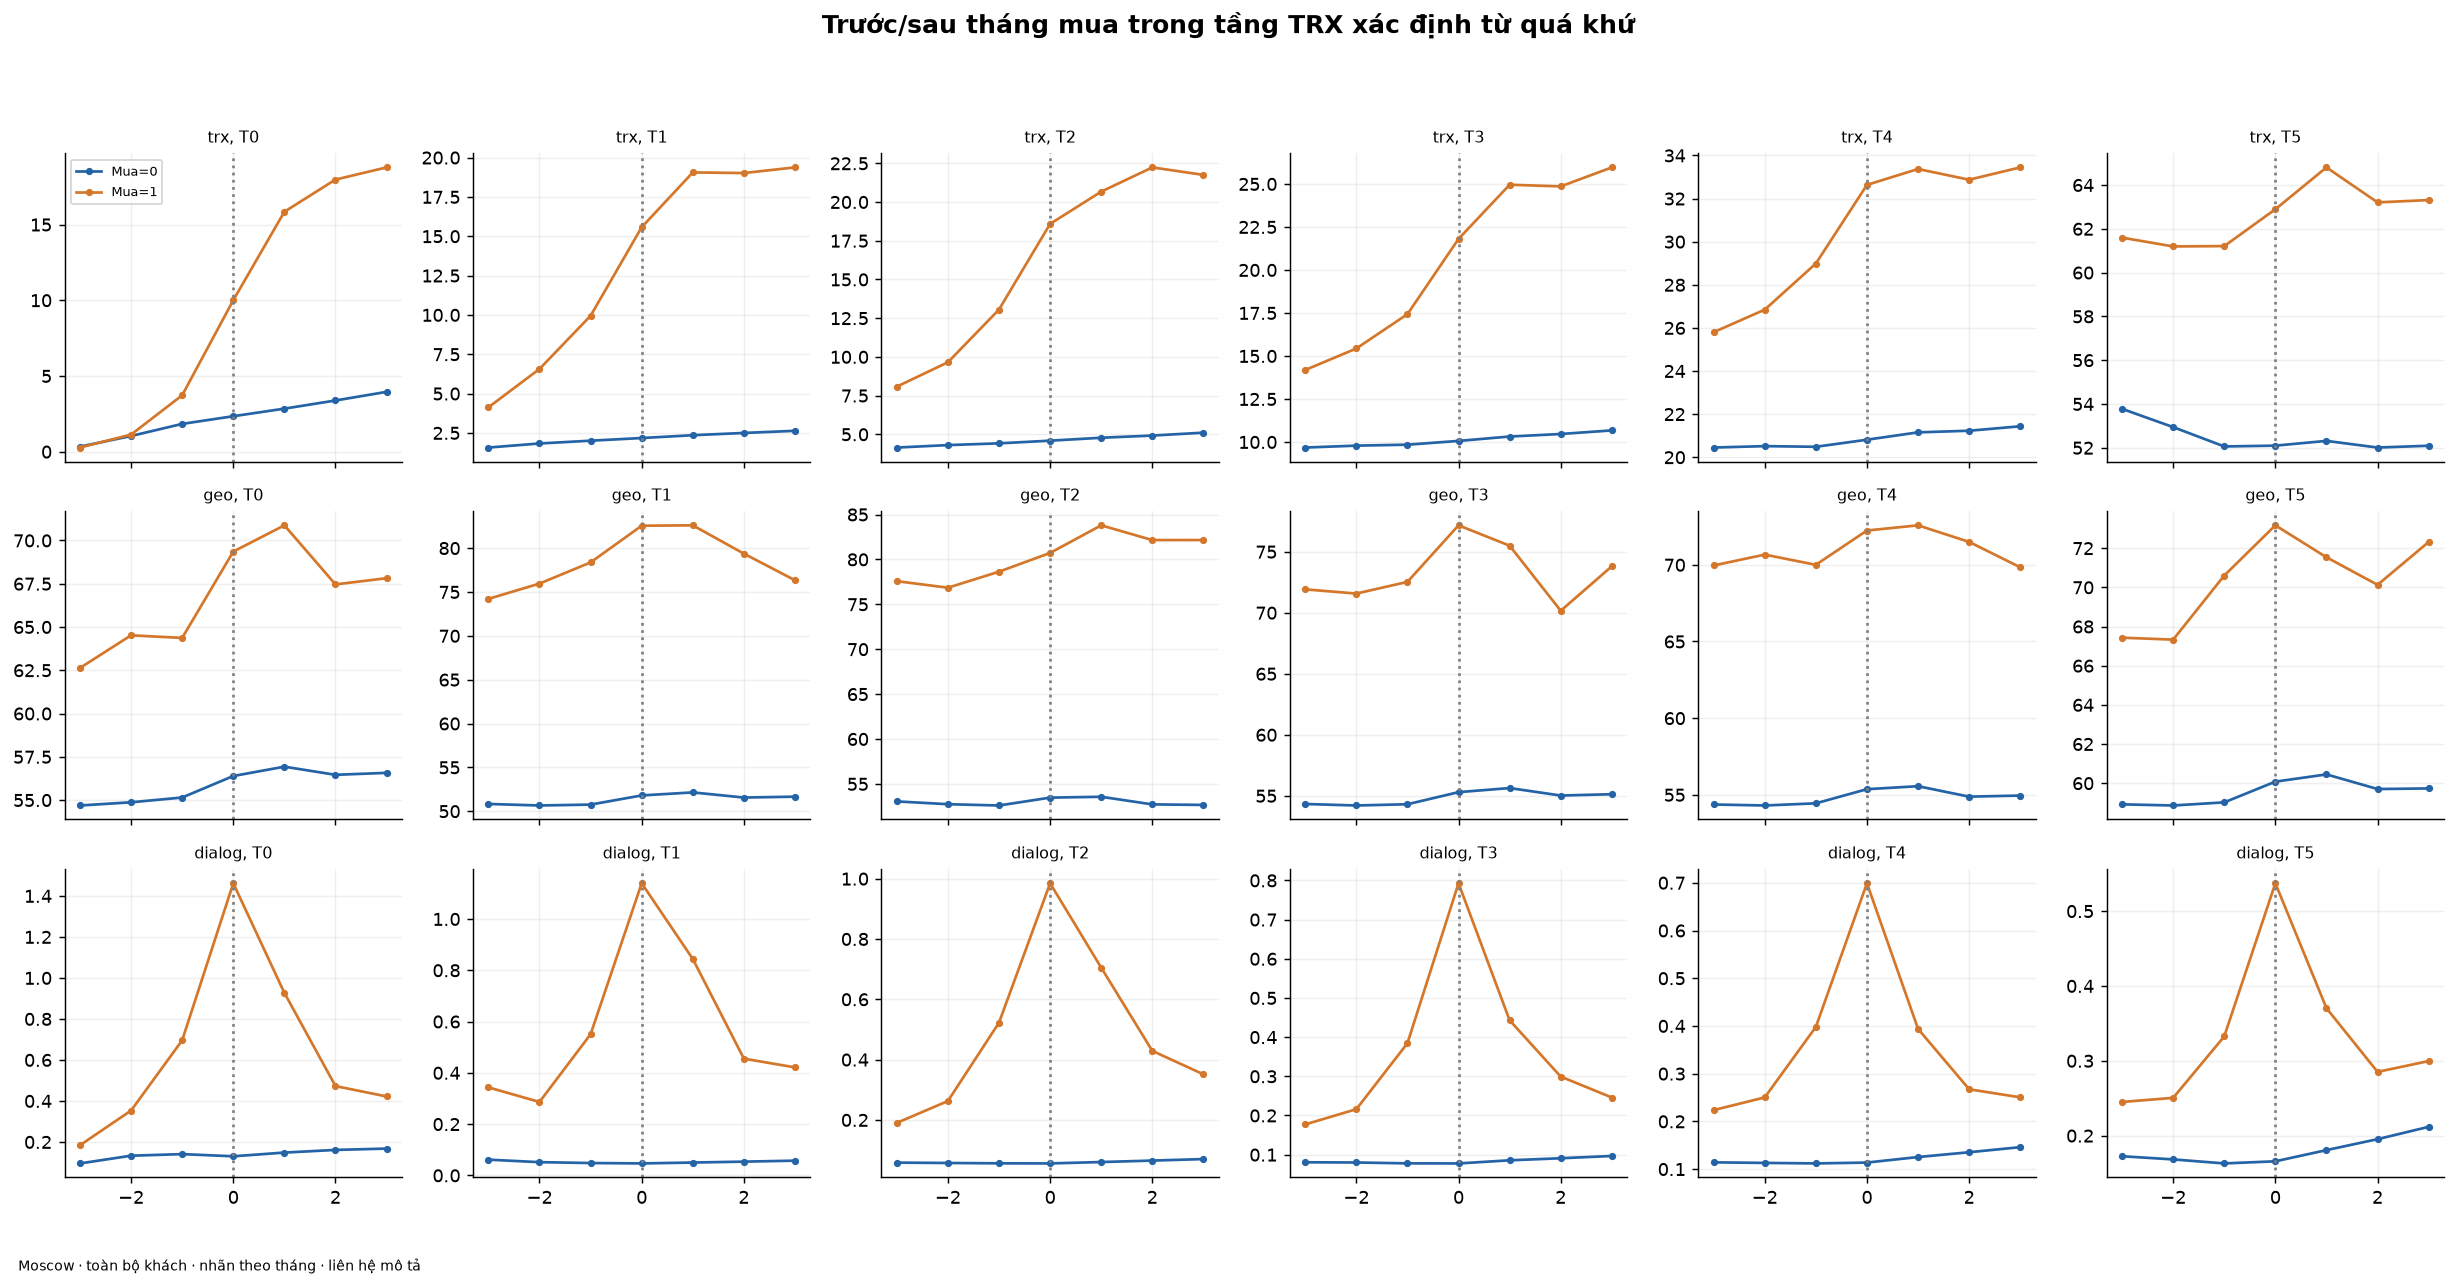

**outputs/eda_figures_moscow/geohash_4_monthly_concentration_novelty.png**

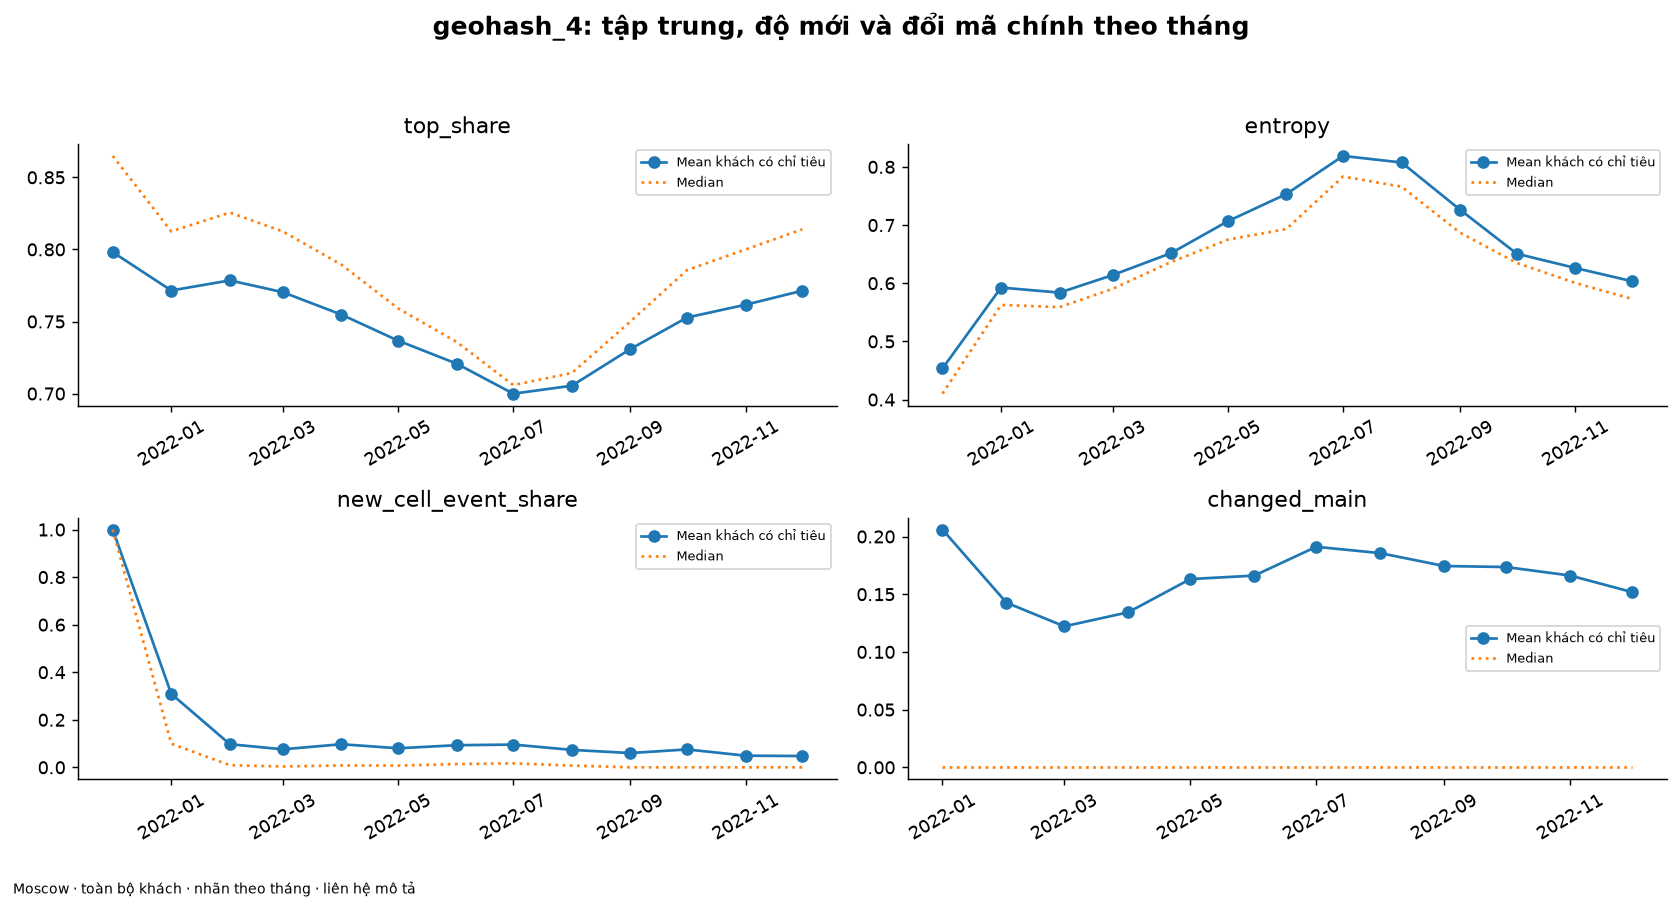

**outputs/eda_figures_moscow/geohash_5_monthly_concentration_novelty.png**

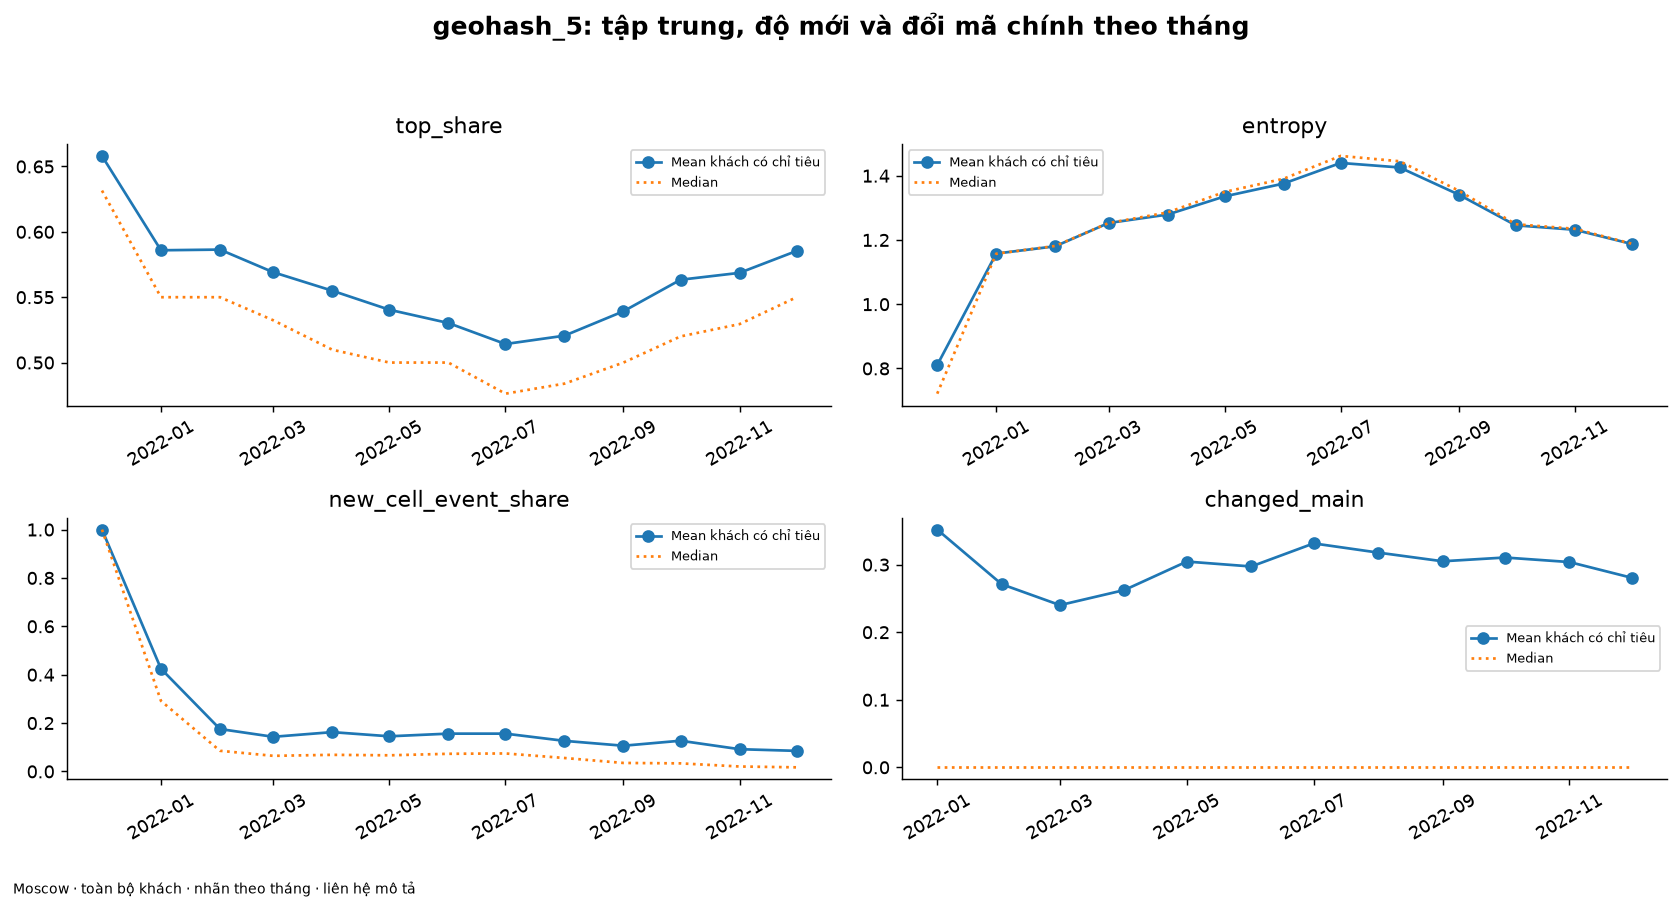

**outputs/eda_figures_moscow/geohash_6_monthly_concentration_novelty.png**

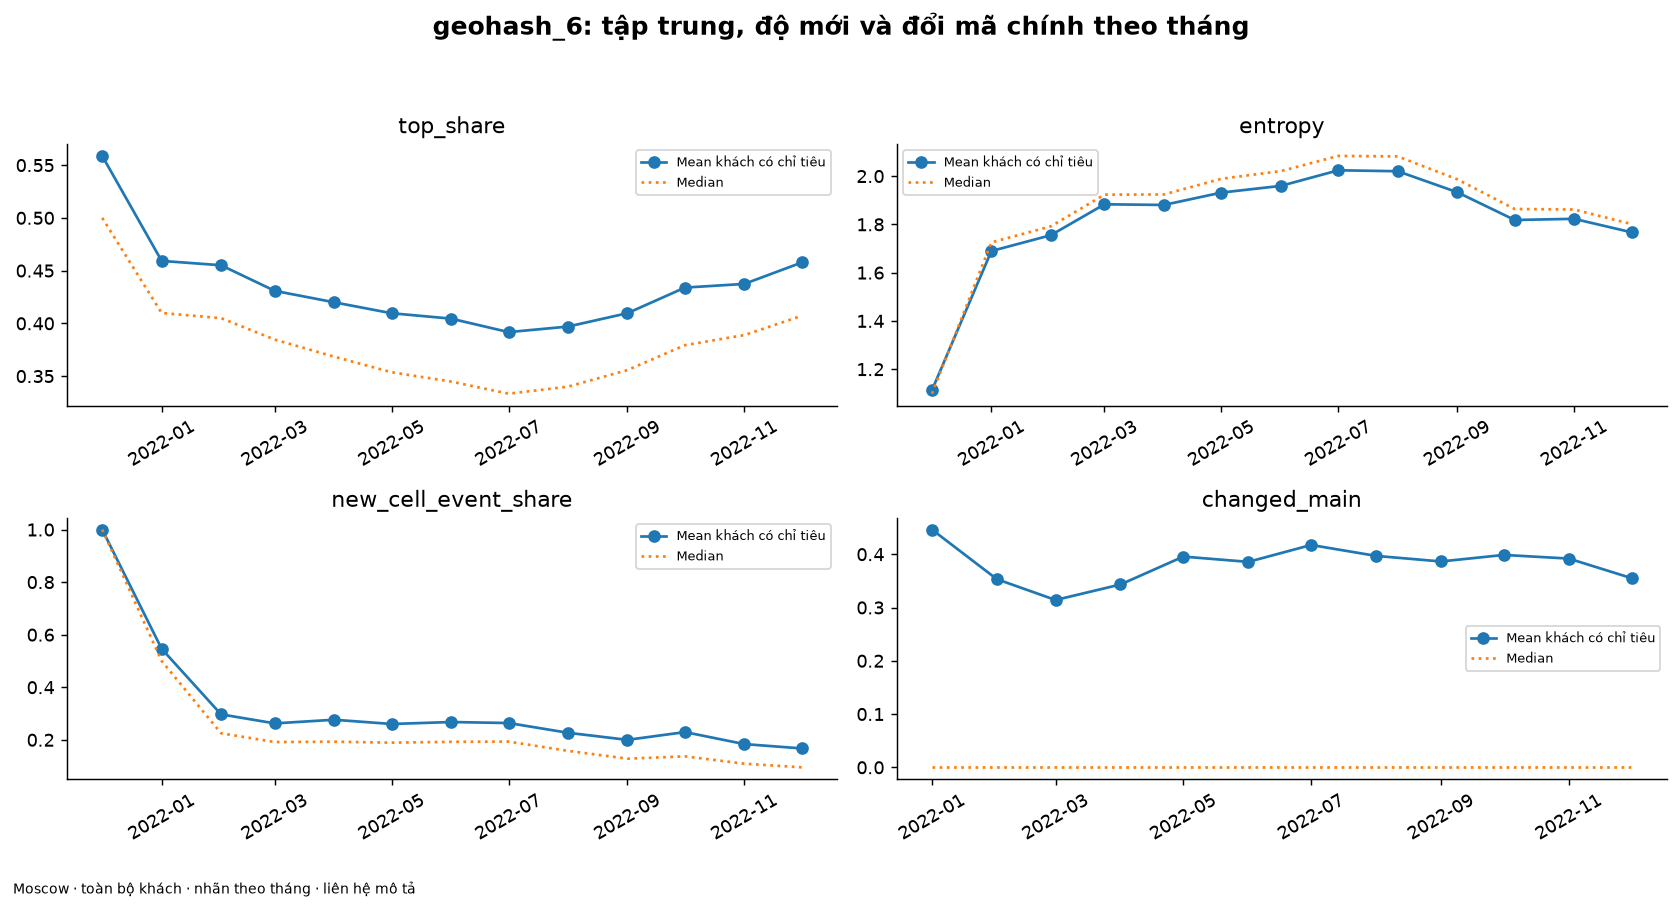

**outputs/eda_figures_moscow/baseline_event_type_new_cells.csv** — 5 dòng đầu

,metric,anchor,lag,purchase,population,observed,unavailable,mean,median,baseline_eligible,baseline_insufficient,baseline_unseen,baseline_zero,delta_mean,increase,decrease,unchanged
0,event_type_new_cells,2022-02-01,-3,0,99183,99183,0,0.159271,0.0,99183,0,15864,87933,0.074569,0.109243,0.089108,0.801649
1,event_type_new_cells,2022-02-01,-3,1,1041,1041,0,0.370797,0.0,1041,0,186,754,0.146494,0.198847,0.193084,0.608069
2,event_type_new_cells,2022-02-01,-2,0,99183,99183,0,0.164907,0.0,99183,0,15864,87933,0.080205,0.116240,0.090066,0.793694
3,event_type_new_cells,2022-02-01,-2,1,1041,1041,0,0.383285,0.0,1041,0,186,754,0.158982,0.213256,0.199808,0.586936
4,event_type_new_cells,2022-02-01,-1,0,99183,99183,0,0.135910,0.0,99183,0,15864,87933,0.051208,0.096609,0.095036,0.808354


**outputs/eda_figures_moscow/baseline_event_type_unique_cells.csv** — 5 dòng đầu

,metric,anchor,lag,purchase,population,observed,unavailable,mean,median,baseline_eligible,baseline_insufficient,baseline_unseen,baseline_zero,delta_mean,increase,decrease,unchanged
0,event_type_unique_cells,2022-02-01,-3,0,99183,99183,0,2.666132,2.0,99183,0,15864,26255,0.157517,0.283486,0.222629,0.493885
1,event_type_unique_cells,2022-02-01,-3,1,1041,1041,0,4.426513,4.0,1041,0,186,270,0.587896,0.397695,0.235351,0.366955
2,event_type_unique_cells,2022-02-01,-2,0,99183,99183,0,2.734884,2.0,99183,0,15864,26255,0.226269,0.311928,0.213766,0.474305
3,event_type_unique_cells,2022-02-01,-2,1,1041,1041,0,4.645533,4.0,1041,0,186,270,0.806916,0.460134,0.215178,0.324688
4,event_type_unique_cells,2022-02-01,-1,0,99183,99183,0,2.617818,2.0,99183,0,15864,26255,0.109202,0.282377,0.257524,0.460099


**outputs/eda_figures_moscow/baseline_geohash_4_new_cells.csv** — 5 dòng đầu

,metric,anchor,lag,purchase,population,observed,unavailable,mean,median,baseline_eligible,baseline_insufficient,baseline_unseen,baseline_zero,delta_mean,increase,decrease,unchanged
0,geohash_4_new_cells,2022-02-01,-3,0,99183,0,99183,NaN,NaN,0,99183,0,0,NaN,NaN,NaN,NaN
1,geohash_4_new_cells,2022-02-01,-3,1,1041,0,1041,NaN,NaN,0,1041,0,0,NaN,NaN,NaN,NaN
2,geohash_4_new_cells,2022-02-01,-2,0,99183,0,99183,NaN,NaN,0,99183,0,0,NaN,NaN,NaN,NaN
3,geohash_4_new_cells,2022-02-01,-2,1,1041,0,1041,NaN,NaN,0,1041,0,0,NaN,NaN,NaN,NaN
4,geohash_4_new_cells,2022-02-01,-1,0,99183,99183,0,1.090661,0.0,0,99183,0,0,NaN,NaN,NaN,NaN


... (29 outputs left out)

,month,customers,mean_entropy,mean_topshare,mean_new_event_share,changed_main_defined,changed_main_share
0,2021-12-01,48668,1.113292,0.558718,1.000000,0,NaN
1,2022-01-01,59802,1.689482,0.459205,0.546253,48433,0.446266
2,2022-02-01,59959,1.755133,0.455078,0.296812,57771,0.353101
3,2022-03-01,56327,1.883177,0.430813,0.262499,54508,0.314064
4,2022-04-01,58752,1.880462,0.419971,0.276343,54001,0.343197


**outputs/eda_figures_moscow/monthly_categorical_feature_coverage.csv** — 5 dòng đầu

,source,column,metric,defined_customer_months,undefined_customer_months,median
0,geo,geohash_4,unique_cells,1202688,1302912,1.000000
1,geo,geohash_4,top_share,697180,1808420,0.775701
2,geo,geohash_4,entropy,697180,1808420,0.646563
3,geo,geohash_4,hhi,697180,1808420,0.629630
4,geo,geohash_4,new_cells,1202688,1302912,0.000000


File kết quả khác: `outputs/eda_figures_moscow/baseline_event_type_new_cells.md`, `outputs/eda_figures_moscow/baseline_event_type_unique_cells.md`, `outputs/eda_figures_moscow/baseline_geohash_4_new_cells.md`, `outputs/eda_figures_moscow/baseline_geohash_4_unique_cells.md`, `outputs/eda_figures_moscow/event_event_type_new_cells.md`, `outputs/eda_figures_moscow/event_event_type_new_cells_by_anchor.md`, `outputs/eda_figures_moscow/event_event_type_unique_cells.md`, `outputs/eda_figures_moscow/event_event_type_unique_cells_by_anchor.md`, `outputs/eda_figures_moscow/event_geohash_4_new_cells.md`, `outputs/eda_figures_moscow/event_geohash_4_new_cells_by_anchor.md`, `outputs/eda_figures_moscow/event_geohash_4_unique_cells.md`, `outputs/eda_figures_moscow/event_geohash_4_unique_cells_by_anchor.md`, `outputs/eda_figures_moscow/event_type_monthly_concentration_novelty.md`, `outputs/eda_figures_moscow/event_type_monthly_profiles.parquet`, `outputs/eda_figures_moscow/execution_status.json`, `outputs/eda_figures_moscow/fixed_past_trx_strata_event_study.md`, `outputs/eda_figures_moscow/geohash_4_monthly_concentration_novelty.md`, `outputs/eda_figures_moscow/geohash_4_monthly_profiles.parquet`, `outputs/eda_figures_moscow/geohash_5_monthly_concentration_novelty.md`, `outputs/eda_figures_moscow/geohash_5_monthly_profiles.parquet`, `outputs/eda_figures_moscow/geohash_6_monthly_concentration_novelty.md`, `outputs/eda_figures_moscow/geohash_6_monthly_profiles.parquet`

In [10]:
show_generated_results(__eda_started_ns, 'src/scripts/extend_eda_monthly_features.py')

## Extend Eda Paired Checks

Nguồn: `src/scripts/extend_eda_paired_checks.py`. Chạy các ô của phần này theo thứ tự.

In [11]:
__file__ = str(ROOT / 'src/scripts/extend_eda_paired_checks.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [12]:
"""Paired before/after, client-cluster bootstrap, monthly placebo and sensitivity."""
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from complete_eda_figures_moscow import load, OUT, BASE, publish, INDEX


def main():
    ids, months, arrays, y = load()
    inventory = pd.read_csv(BASE/'source_inventory.csv')
    for r in inventory.itertuples():
        if r.first_month_partial: arrays[r.source][:, months.get_loc(pd.Timestamp(r.first_month))] = np.nan
    anchors = np.where(np.isfinite(y).any(axis=0))[0]
    # Each column stores cluster sufficient statistics; all observations of a client travel together.
    stats = []; specs = []; rows = []
    for metric, a in arrays.items():
        for b in [0, 1]:
            sums = np.zeros(len(ids)); counts = np.zeros(len(ids))
            all_delta = []; by_anchor = []
            for t in anchors:
                valid = (y[:, t] == b)
                if t == 0 or t+1 >= a.shape[1]:
                    rows.append(dict(metric=metric, purchase=b, anchor=str(months[t].date()), population=int(valid.sum()), paired=0,
                                     mean_delta=np.nan, median_delta=np.nan, increase=np.nan, decrease=np.nan, unchanged=np.nan))
                    continue
                valid &= np.isfinite(a[:, t-1]) & np.isfinite(a[:, t+1])
                delta = a[:, t+1]-a[:, t-1]
                sums[valid] += delta[valid]; counts[valid] += 1
                v = delta[valid]; all_delta.append(v)
                by_anchor.append(float(v.mean()) if len(v) else np.nan)
                tol = 1e-6*np.maximum(1, np.abs(a[valid, t-1]))
                rows.append(dict(metric=metric, purchase=b, anchor=str(months[t].date()),
                    population=int((y[:, t]==b).sum()), paired=int(valid.sum()),
                    mean_delta=float(v.mean()) if len(v) else np.nan, median_delta=float(np.median(v)) if len(v) else np.nan,
                    increase=float((v>tol).mean()) if len(v) else np.nan,
                    decrease=float((v < -tol).mean()) if len(v) else np.nan,
                    unchanged=float((np.abs(v)<=tol).mean()) if len(v) else np.nan))
            stats.extend([sums, counts]); specs.append((metric, b))
    matrix = np.column_stack(stats)
    rng = np.random.default_rng(42)
    boots = []
    for start in range(0, 2000, 20):
        weights = rng.multinomial(len(ids), np.full(len(ids), 1/len(ids)), size=min(20,2000-start))
        totals = weights @ matrix
        boots.append(np.divide(totals[:, ::2], totals[:, 1::2], out=np.full((len(weights),len(specs)),np.nan), where=totals[:, 1::2]>0))
        if start % 400 == 0: print('Bootstrap', start, flush=True)
    boot = np.vstack(boots)
    summary = []
    for k, (metric, b) in enumerate(specs):
        sums, counts = matrix[:, 2*k], matrix[:, 2*k+1]
        per_client = np.divide(sums, counts, out=np.full(len(ids),np.nan), where=counts>0)
        summary.append(dict(metric=metric, purchase=b, paired_customer_months=int(counts.sum()),
            unique_paired_customers=int((counts>0).sum()),
            paired_mean=float(sums.sum()/counts.sum()),
            low=float(np.nanquantile(boot[:,k], .025)), high=float(np.nanquantile(boot[:,k], .975)),
            customer_equal_mean=float(np.nanmean(per_client))))
    d = pd.DataFrame(rows); s = pd.DataFrame(summary)
    d.to_csv(OUT/'paired_by_anchor.csv', index=False)
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, metric in zip(axes.flat, arrays):
        q = s[s.metric==metric]
        ax.errorbar(q.purchase, q.paired_mean, yerr=[q.paired_mean-q.low,q.high-q.paired_mean], fmt='o', capsize=5, label='Trọng số khách–tháng')
        ax.scatter(q.purchase+.07, q.customer_equal_mean, marker='x', label='Mỗi khách cùng trọng số')
        ax.axhline(0,color='gray',ls=':'); ax.set_xticks([0,1], ['Không mua', 'Mua']); ax.set_title(metric)
        ax.set_ylabel('Tháng +1 trừ tháng −1'); ax.legend(fontsize=7)
    insight = '; '.join(f"{r.metric}, mua={r.purchase}: {r.paired_mean:.4g} [{r.low:.4g}; {r.high:.4g}]" for r in s.itertuples())
    publish('paired_before_after_bootstrap', fig, s, 'So trước/sau trên cùng khách và kiểm tra trọng số',
        'Tại mỗi tháng neo, ghép cùng khách có tháng −1 và +1 đủ nguồn; giữ đủ 12 tháng neo trong paired_by_anchor.csv, '
        'không đủ hai phía có paired=0. Ước lượng chính gộp khách–tháng đủ cặp. Bootstrap multinomial 2.000 lượt '
        'trên 100.224 khách, seed42; mọi tháng của cùng khách mang cùng trọng số. CI percentile 95%. '
        'Dấu x cho trung bình chênh lệch mỗi khách, sau đó cân bằng trọng số giữa khách.',
        'Kiểm tra chênh lệch có còn khi giữ cùng tập khách ở hai phía và khi khách mua lặp không có trọng số lớn hơn.',
        insight,
        'Đây chưa phải tác động mua; nhóm mua/không mua còn khác thành phần. CI từng ước lượng chưa hiệu chỉnh đa kiểm định. '
        'Tháng 0 không nằm trong chênh lệch. Không đủ hai phía không bị gán zero.')
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    for ax, metric in zip(axes.flat, arrays):
        for b, color in [(0,'#2463a6'),(1,'#d4772b')]:
            q=d[(d.metric==metric)&(d.purchase==b)]
            ax.plot(pd.to_datetime(q.anchor),q.mean_delta,'o-',color=color,label=f'Mua={b}, mean')
            ax.plot(pd.to_datetime(q.anchor),q.median_delta,':',color=color,label=f'Mua={b}, median')
        ax.set_title(metric); ax.axhline(0,color='gray',ls=':'); ax.tick_params(axis='x',rotation=30); ax.legend(fontsize=7)
    publish('paired_placebo_calendar_sensitivity', fig, d, 'Đối chứng tháng neo không mua và độ nhạy mean / median',
        'Mỗi ô giữ mọi tháng nhãn. Tháng neo không mua là nhóm đối chứng lịch cùng kỳ; không chọn ngẫu nhiên vài tháng. '
        'Cùng khách được ghép −1/+1; CSV có n đủ cặp, mean, median và tỷ lệ tăng/giảm/không đổi.',
        'Đối chiếu thay đổi quanh tháng mua với biến động cùng lịch của nhóm không mua, tránh gộp mọi mùa vụ vào mua.',
        'Hình cho phép kiểm tra tính nhất quán dấu theo từng tháng neo. Đọc các đoạn thiếu dữ liệu cùng paired=0; '
        'không khái quát đường trung bình khi mean/median hoặc các tháng khác dấu.',
        'Đối chứng này chưa ghép tầng TRX/độ dài lịch sử; không phải placebo nhân quả. Chưa có CI riêng từng tháng.')
    old=pd.read_csv(OUT/'figure_index.csv')
    idx=pd.concat([old,pd.DataFrame(INDEX)]).drop_duplicates('figure',keep='last');idx.to_csv(OUT/'figure_index.csv',index=False)
    status=json.loads((OUT/'execution_status.json').read_text(encoding='utf-8'))
    status['done']+=['paired_month_minus1_plus1','client_cluster_bootstrap_2000_monthly_metrics','calendar_nonbuyer_mean_median_weight_sensitivity']
    status['figures']=len(idx)
    status['pending']=[x for x in status['pending'] if x != 'client_bootstrap_2000']
    (OUT/'execution_status.json').write_text(json.dumps(status,ensure_ascii=False,indent=2),encoding='utf-8')


if __name__=='__main__': main()

Bootstrap 0


Bootstrap 400


Bootstrap 800


Bootstrap 1200


Bootstrap 1600


Saved paired_before_after_bootstrap


Saved paired_placebo_calendar_sensitivity


### Kết quả: `src/scripts/extend_eda_paired_checks.py`

**outputs/eda_figures_moscow/paired_before_after_bootstrap.png**

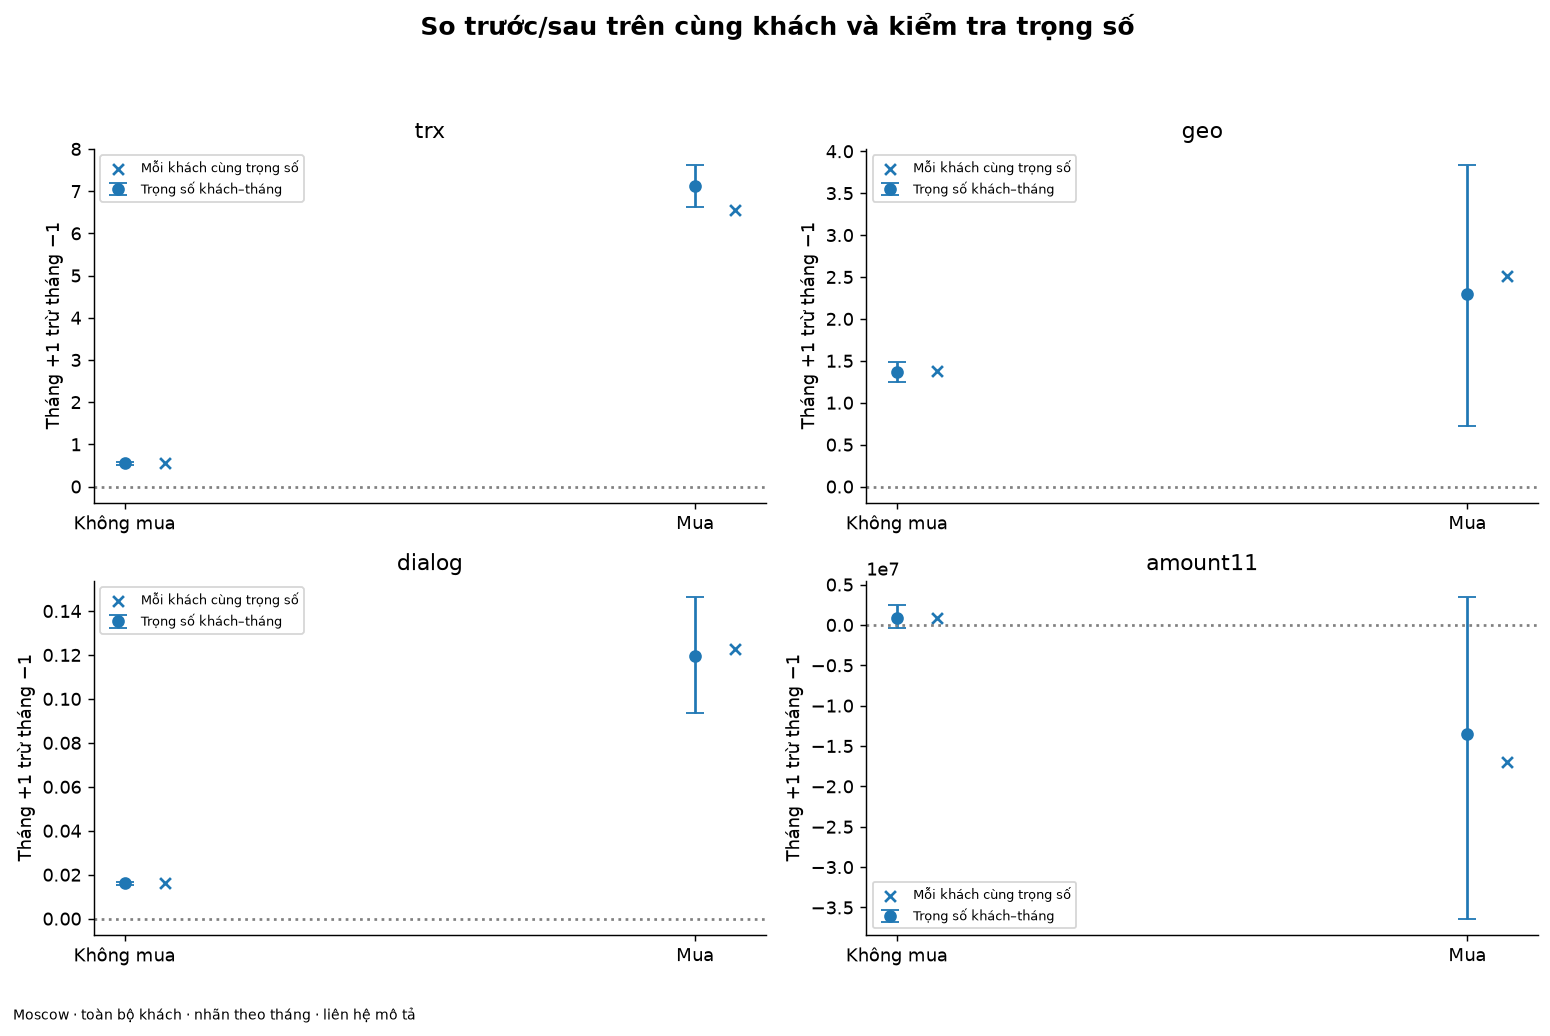

**outputs/eda_figures_moscow/paired_placebo_calendar_sensitivity.png**

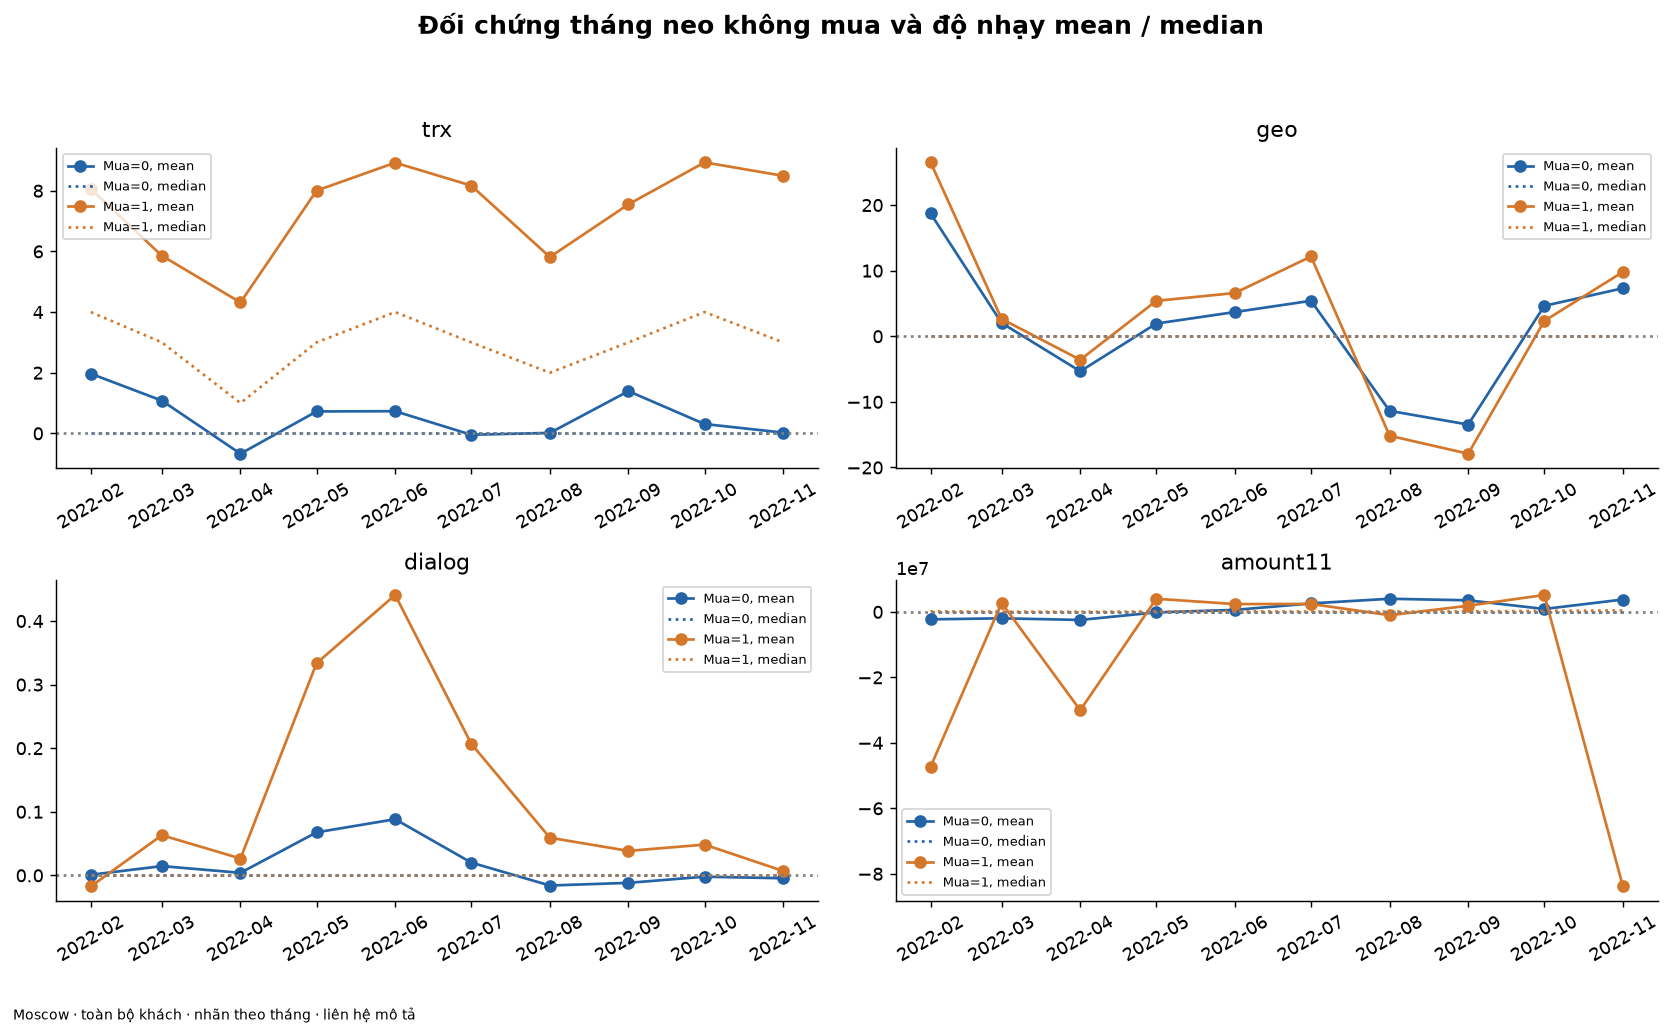

**outputs/eda_figures_moscow/figure_index.csv** — 5 dòng đầu

,figure,title,data,explanation
0,baseline_amount11,amount11: thay đổi so với nền của chính khách,baseline_amount11.csv,baseline_amount11.md
1,baseline_dialog,dialog: thay đổi so với nền của chính khách,baseline_dialog.csv,baseline_dialog.md
2,baseline_geo,geo: thay đổi so với nền của chính khách,baseline_geo.csv,baseline_geo.md
3,baseline_trx,trx: thay đổi so với nền của chính khách,baseline_trx.csv,baseline_trx.md
4,composition_amount11,amount11: phân rã thay đổi giữa các tháng,composition_amount11.csv,composition_amount11.md


**outputs/eda_figures_moscow/paired_before_after_bootstrap.csv** — 5 dòng đầu

,metric,purchase,paired_customer_months,unique_paired_customers,paired_mean,low,high,customer_equal_mean
0,trx,0,990820,100224,0.552823,0.512880,0.582679,0.566657
1,trx,1,11420,9470,7.125569,6.630326,7.621207,6.561371
2,geo,0,990820,100224,1.364888,1.242931,1.484979,1.375680
3,geo,1,11420,9470,2.297373,0.718998,3.836924,2.515244
4,dialog,0,990820,100224,0.016119,0.015418,0.016815,0.016320


**outputs/eda_figures_moscow/paired_by_anchor.csv** — 5 dòng đầu

,metric,purchase,anchor,population,paired,mean_delta,median_delta,increase,decrease,unchanged
0,trx,0,2022-02-01,99183,99183,1.967061,0.0,0.464011,0.279453,0.256536
1,trx,0,2022-03-01,98657,98657,1.079650,0.0,0.427633,0.312537,0.259830
2,trx,0,2022-04-01,98526,98526,-0.671285,0.0,0.345269,0.403122,0.251609
3,trx,0,2022-05-01,99124,99124,0.722963,0.0,0.399580,0.352538,0.247881
4,trx,0,2022-06-01,99047,99047,0.731017,0.0,0.403899,0.352843,0.243258


**outputs/eda_figures_moscow/paired_placebo_calendar_sensitivity.csv** — 5 dòng đầu

,metric,purchase,anchor,population,paired,mean_delta,median_delta,increase,decrease,unchanged
0,trx,0,2022-02-01,99183,99183,1.967061,0.0,0.464011,0.279453,0.256536
1,trx,0,2022-03-01,98657,98657,1.079650,0.0,0.427633,0.312537,0.259830
2,trx,0,2022-04-01,98526,98526,-0.671285,0.0,0.345269,0.403122,0.251609
3,trx,0,2022-05-01,99124,99124,0.722963,0.0,0.399580,0.352538,0.247881
4,trx,0,2022-06-01,99047,99047,0.731017,0.0,0.403899,0.352843,0.243258


File kết quả khác: `outputs/eda_figures_moscow/execution_status.json`, `outputs/eda_figures_moscow/paired_before_after_bootstrap.md`, `outputs/eda_figures_moscow/paired_placebo_calendar_sensitivity.md`

In [13]:
show_generated_results(__eda_started_ns, 'src/scripts/extend_eda_paired_checks.py')